In [1]:

# ============================================================
# PHASE 6.1 - CELL 1
# Verify project directories and required saved artefacts
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# 1. Confirm Google Drive access
# ------------------------------------------------------------

DRIVE_ROOT = Path("/content/drive")
PROJECT_ROOT = DRIVE_ROOT / "MyDrive" / "AgroVision_FYP2"

if not PROJECT_ROOT.is_dir():
    try:
        from google.colab import drive
        drive.mount(str(DRIVE_ROOT))
    except ImportError as exc:
        raise RuntimeError(
            "Google Drive is not accessible. "
            "Please connect VS Code to the Google Colab runtime."
        ) from exc

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(
        f"AgroVision project directory not found: {PROJECT_ROOT}"
    )

print("=" * 65)
print("PHASE 6.1 - PROJECT ENVIRONMENT VERIFICATION")
print("=" * 65)

print(f"\nProject root: {PROJECT_ROOT}")
print("Google Drive access: VERIFIED")

# ------------------------------------------------------------
# 2. Define existing project directories
# ------------------------------------------------------------

DATA_DIR = PROJECT_ROOT / "plantvillage_preparation"
EXPERIMENT_DIR = PROJECT_ROOT / "model_experiments"

MODEL_NAMES = [
    "ResNet50",
    "MobileNetV2",
    "EfficientNetB0"
]

# ------------------------------------------------------------
# 3. Verify essential Phase 4 and dataset artefacts
# ------------------------------------------------------------

required_files = {
    "Experiment tracker":
        EXPERIMENT_DIR / "phase4_experiment_tracker.csv",

    "Final split manifest":
        DATA_DIR / "final_split_manifest.csv",

    "Class-to-index mapping":
        DATA_DIR / "class_to_index.json",

    "Preprocessing plan":
        DATA_DIR / "preprocessing_augmentation_plan.json"
}

missing_items = []

print("\n" + "-" * 65)
print("REQUIRED ARTEFACT VERIFICATION")
print("-" * 65)

for label, path in required_files.items():
    if path.is_file():
        print(f"[OK] {label}")
        print(f"     {path}")
    else:
        print(f"[MISSING] {label}")
        print(f"          {path}")
        missing_items.append(str(path))

# ------------------------------------------------------------
# 4. Verify selected Stage 2 model directories
# ------------------------------------------------------------

print("\n" + "-" * 65)
print("SELECTED MODEL DIRECTORY VERIFICATION")
print("-" * 65)

for model_name in MODEL_NAMES:

    stage2_dir = EXPERIMENT_DIR / model_name / "stage2"

    print(f"\nModel: {model_name}")

    if stage2_dir.is_dir():

        print("[OK] Stage 2 directory found")

        saved_items = sorted(
            stage2_dir.iterdir(),
            key=lambda p: p.name
        )

        if saved_items:
            print("Saved contents:")

            for item in saved_items:
                item_type = "DIR" if item.is_dir() else "FILE"
                print(f"  [{item_type}] {item.name}")
        else:
            print("[WARNING] Stage 2 directory is empty")
            missing_items.append(str(stage2_dir))

    else:
        print("[MISSING] Stage 2 directory")
        missing_items.append(str(stage2_dir))

# ------------------------------------------------------------
# 5. Final verification status
# ------------------------------------------------------------

print("\n" + "=" * 65)

if missing_items:
    print("VERIFICATION STATUS: INCOMPLETE")
    print(f"Missing or empty artefacts: {len(missing_items)}")

    for item in missing_items:
        print(f"  - {item}")

    raise FileNotFoundError(
        "Resolve the missing artefacts before evaluation."
    )

else:
    print("VERIFICATION STATUS: PASSED")
    print("Required files and Stage 2 directories are accessible.")
    print("No model training or test evaluation was performed.")

print("=" * 65)


Mounted at /content/drive
PHASE 6.1 - PROJECT ENVIRONMENT VERIFICATION

Project root: /content/drive/MyDrive/AgroVision_FYP2
Google Drive access: VERIFIED

-----------------------------------------------------------------
REQUIRED ARTEFACT VERIFICATION
-----------------------------------------------------------------
[OK] Experiment tracker
     /content/drive/MyDrive/AgroVision_FYP2/model_experiments/phase4_experiment_tracker.csv
[OK] Final split manifest
     /content/drive/MyDrive/AgroVision_FYP2/plantvillage_preparation/final_split_manifest.csv
[OK] Class-to-index mapping
     /content/drive/MyDrive/AgroVision_FYP2/plantvillage_preparation/class_to_index.json
[OK] Preprocessing plan
     /content/drive/MyDrive/AgroVision_FYP2/plantvillage_preparation/preprocessing_augmentation_plan.json

-----------------------------------------------------------------
SELECTED MODEL DIRECTORY VERIFICATION
-----------------------------------------------------------------

Model: ResNet50
[OK] Stage

In [2]:

# ============================================================
# PHASE 6.1 - CELL 2
# Verify dataset configuration and Phase 4 model metadata
# ============================================================

import json
import pandas as pd

print("=" * 65)
print("PHASE 6.1 - DATASET AND MODEL CONFIGURATION VERIFICATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Verify class-to-index mapping
# ------------------------------------------------------------

mapping_path = DATA_DIR / "class_to_index.json"

with open(mapping_path, "r", encoding="utf-8") as f:
    class_to_index = json.load(f)

NUM_CLASSES = len(class_to_index)
class_indices = sorted(class_to_index.values())

assert NUM_CLASSES == 38, (
    f"Expected 38 classes, found {NUM_CLASSES}"
)

assert class_indices == list(range(NUM_CLASSES)), (
    "Class indices must be unique and consecutive from 0 to 37."
)

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

print("\nCLASS MAPPING")
print(f"Total classes: {NUM_CLASSES}")
print(f"Index range: {min(class_indices)} to {max(class_indices)}")
print("Class mapping: VERIFIED")

# ------------------------------------------------------------
# 2. Inspect saved preprocessing configuration
# ------------------------------------------------------------

plan_path = DATA_DIR / "preprocessing_augmentation_plan.json"

with open(plan_path, "r", encoding="utf-8") as f:
    preprocessing_plan = json.load(f)

print("\nPREPROCESSING PLAN")
print("Image size:",
      preprocessing_plan.get("input_image_size"))
print("Colour mode:",
      preprocessing_plan.get("colour_mode"))
print("Model-specific preprocessing:",
      preprocessing_plan.get("model_specific_preprocessing"))
print("Validation augmentation:",
      preprocessing_plan.get("validation_augmentation"))
print("Test augmentation:",
      preprocessing_plan.get("test_augmentation"))
print("Configuration status:",
      preprocessing_plan.get("status"))

# ------------------------------------------------------------
# 3. Verify recorded dataset split counts
# ------------------------------------------------------------

split_summary_path = DATA_DIR / "split_summary.csv"
split_summary = pd.read_csv(split_summary_path)

expected_counts = {
    "train": 37978,
    "validation": 8155,
    "test": 8151
}

actual_counts = dict(
    zip(split_summary["split"], split_summary["images"])
)

print("\nDATASET SPLIT SUMMARY")
print(split_summary.to_string(index=False))

assert actual_counts == expected_counts, (
    f"Split counts do not match: {actual_counts}"
)

assert sum(actual_counts.values()) == 54284, (
    "Dataset total does not match 54,284 images."
)

print("Recorded split counts: VERIFIED")

# ------------------------------------------------------------
# 4. Verify each model's Phase 4 experiment summary
# ------------------------------------------------------------

print("\n" + "-" * 65)
print("PHASE 4 MODEL METADATA")
print("-" * 65)

model_configs = {}

for model_name in MODEL_NAMES:

    summary_path = (
        EXPERIMENT_DIR
        / model_name
        / "experiment_summary.json"
    )

    with open(summary_path, "r", encoding="utf-8") as f:
        summary = json.load(f)

    model_configs[model_name] = summary

    assert summary["architecture"] == model_name
    assert summary["num_classes"] == NUM_CLASSES

    assert summary["training_samples"] == 37978
    assert summary["validation_samples"] == 8155
    assert summary["test_samples_reserved"] == 8151

    selected_checkpoint = Path(
        summary["model_selection"]["selected_checkpoint"]
    )

    expected_checkpoint = (
        EXPERIMENT_DIR
        / model_name
        / "stage2"
        / "best_model.keras"
    )

    assert selected_checkpoint == expected_checkpoint, (
        f"Unexpected selected checkpoint for {model_name}"
    )

    assert selected_checkpoint.is_file(), (
        f"Missing selected checkpoint for {model_name}"
    )

    assert summary["test_evaluation_completed"] is False, (
        f"Test evaluation is already recorded for {model_name}"
    )

    print(f"\nModel: {model_name}")
    print(f"Image size: {summary['image_size']}")
    print(f"Number of classes: {summary['num_classes']}")
    print("Selected stage:",
          summary["model_selection"]["selected_stage"])
    print("Selection criterion:",
          summary["model_selection"]["criterion"])
    print("Test evaluation recorded:",
          summary["test_evaluation_completed"])
    print("External evaluation recorded:",
          summary["external_evaluation_completed"])

# ------------------------------------------------------------
# 5. Cross-check shared model configurations
# ------------------------------------------------------------

image_sizes = {
    tuple(config["image_size"])
    for config in model_configs.values()
}

assert len(image_sizes) == 1, (
    "Models have different recorded input image sizes."
)

recorded_image_size = next(iter(image_sizes))

assert list(recorded_image_size) == preprocessing_plan[
    "input_image_size"
], (
    "Model image size differs from preprocessing plan."
)

print("\n" + "=" * 65)
print("CONFIGURATION VERIFICATION: PASSED")
print(f"Recorded input size: {recorded_image_size}")
print(f"Classification classes: {NUM_CLASSES}")
print(f"Dataset images: {sum(actual_counts.values()):,}")
print("All three experiment summaries are consistent.")
print("No images were loaded or evaluated.")
print("=" * 65)


PHASE 6.1 - DATASET AND MODEL CONFIGURATION VERIFICATION

CLASS MAPPING
Total classes: 38
Index range: 0 to 37
Class mapping: VERIFIED

PREPROCESSING PLAN
Image size: [160, 160]
Colour mode: RGB
Model-specific preprocessing: tf.keras.applications.resnet50.preprocess_input
Validation augmentation: False
Test augmentation: False
Configuration status: Planned configuration; model training not started

DATASET SPLIT SUMMARY
     split  images  percentage
     train   37978       69.96
validation    8155       15.02
      test    8151       15.02
Recorded split counts: VERIFIED

-----------------------------------------------------------------
PHASE 4 MODEL METADATA
-----------------------------------------------------------------

Model: ResNet50
Image size: [160, 160]
Number of classes: 38
Selected stage: Stage 2 - Fine-Tuning
Selection criterion: Minimum validation loss
Test evaluation recorded: False
External evaluation recorded: False

Model: MobileNetV2
Image size: [160, 160]
Number o

In [3]:

# ============================================================
# PHASE 6.1 - CELL 3
# Verify saved PlantVillage split integrity
# ============================================================

import pandas as pd

print("=" * 65)
print("PHASE 6.1 - FINAL DATASET SPLIT INTEGRITY")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load the original Phase 2 split manifest
# ------------------------------------------------------------

manifest_path = DATA_DIR / "final_split_manifest.csv"

manifest = pd.read_csv(manifest_path)

required_columns = {
    "filepath",
    "sha256",
    "plantvillage_class",
    "split_group_id",
    "split"
}

missing_columns = required_columns - set(manifest.columns)

assert not missing_columns, (
    f"Missing manifest columns: {missing_columns}"
)

print("\nMANIFEST INFORMATION")
print(f"Total records: {len(manifest):,}")
print(f"Total columns: {len(manifest.columns)}")
print("Required columns: VERIFIED")

assert len(manifest) == 54284

assert not manifest[
    list(required_columns)
].isna().any().any(), (
    "Missing values found in essential manifest columns."
)

# ------------------------------------------------------------
# 2. Verify split assignments and counts
# ------------------------------------------------------------

split_order = ["train", "validation", "test"]

actual_split_counts = (
    manifest["split"]
    .value_counts()
    .reindex(split_order, fill_value=0)
)

expected_split_counts = pd.Series({
    "train": 37978,
    "validation": 8155,
    "test": 8151
})

assert set(manifest["split"].unique()) == set(split_order)

assert actual_split_counts.equals(
    expected_split_counts
), "Dataset split counts do not match the saved configuration."

print("\nDATASET SPLIT DISTRIBUTION")

split_distribution = pd.DataFrame({
    "split": split_order,
    "images": actual_split_counts.values,
    "percentage": (
        actual_split_counts.values / len(manifest) * 100
    ).round(2)
})

display(split_distribution)

# ------------------------------------------------------------
# 3. Check exact duplicate image records
# ------------------------------------------------------------

duplicate_hashes = manifest["sha256"].duplicated().sum()
duplicate_paths = manifest["filepath"].duplicated().sum()

print("\nDUPLICATE RECORD VERIFICATION")
print(f"Duplicate SHA-256 records: {duplicate_hashes}")
print(f"Duplicate file paths: {duplicate_paths}")

assert duplicate_hashes == 0, (
    "Duplicate image hashes detected in the split manifest."
)

assert duplicate_paths == 0, (
    "Duplicate file paths detected in the split manifest."
)

# ------------------------------------------------------------
# 4. Verify related-image group separation
# ------------------------------------------------------------

group_split_counts = (
    manifest.groupby("split_group_id")["split"]
    .nunique()
)

groups_crossing_splits = int(
    (group_split_counts > 1).sum()
)

print("\nGROUP-LEVEL LEAKAGE VERIFICATION")
print(
    "Unique identified image groups:",
    manifest["split_group_id"].nunique()
)
print(
    "Groups crossing dataset splits:",
    groups_crossing_splits
)

assert groups_crossing_splits == 0, (
    "Related-image groups were assigned to multiple splits."
)

# ------------------------------------------------------------
# 5. Verify class mapping and class coverage
# ------------------------------------------------------------

manifest_classes = set(
    manifest["plantvillage_class"].unique()
)

mapping_classes = set(class_to_index.keys())

assert manifest_classes == mapping_classes, (
    "Manifest classes do not match the saved class mapping."
)

class_split_counts = pd.crosstab(
    manifest["plantvillage_class"],
    manifest["split"]
).reindex(columns=split_order, fill_value=0)

assert len(class_split_counts) == NUM_CLASSES

assert (class_split_counts > 0).all().all(), (
    "At least one class is absent from a dataset split."
)

print("\nCLASS COVERAGE VERIFICATION")
print("Total classes:", len(class_split_counts))

for split_name in split_order:
    print(
        f"{split_name.capitalize()} classes:",
        int((class_split_counts[split_name] > 0).sum())
    )

# ------------------------------------------------------------
# 6. Inspect reserved test metadata only
# ------------------------------------------------------------

test_manifest = manifest.loc[
    manifest["split"] == "test"
].copy()

print("\nRESERVED TEST SET METADATA")
print(f"Reserved test images: {len(test_manifest):,}")
print(
    "Reserved test classes:",
    test_manifest["plantvillage_class"].nunique()
)

print("\nExample recorded image paths:")

for path in test_manifest["filepath"].head(3):
    print(f"  {path}")

print("\nNo test images were opened or processed.")

# ------------------------------------------------------------
# 7. Final integrity verification
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DATASET SPLIT INTEGRITY: PASSED")
print("Total images: 54,284")
print("Classes represented: 38")
print("Duplicate image records: 0")
print("Identified groups crossing splits: 0")
print("Test images evaluated: 0")
print("=" * 65)


PHASE 6.1 - FINAL DATASET SPLIT INTEGRITY

MANIFEST INFORMATION
Total records: 54,284
Total columns: 6
Required columns: VERIFIED

DATASET SPLIT DISTRIBUTION


,split,images,percentage
0,train,37978,69.96
1,validation,8155,15.02
2,test,8151,15.02



DUPLICATE RECORD VERIFICATION
Duplicate SHA-256 records: 0
Duplicate file paths: 0

GROUP-LEVEL LEAKAGE VERIFICATION
Unique identified image groups: 54277
Groups crossing dataset splits: 0

CLASS COVERAGE VERIFICATION
Total classes: 38
Train classes: 38
Validation classes: 38
Test classes: 38

RESERVED TEST SET METADATA
Reserved test images: 8,151
Reserved test classes: 38

Example recorded image paths:
  /kaggle/input/plantvillage-dataset/color/Apple___Cedar_apple_rust/ea119d19-1b3a-4767-af1d-e8b148a3bb8d___FREC_C.Rust 3579.JPG
  /kaggle/input/plantvillage-dataset/color/Tomato___Tomato_Yellow_Leaf_Curl_Virus/55e1ab24-e4bb-4228-8a3d-b8c6ebb9a527___UF.GRC_YLCV_Lab 01299.JPG
  /kaggle/input/plantvillage-dataset/color/Grape___Leaf_blight_(Isariopsis_Leaf_Spot)/9b979112-411f-4bf3-94cf-b3d99382a046___FAM_L.Blight 1495.JPG

No test images were opened or processed.

DATASET SPLIT INTEGRITY: PASSED
Total images: 54,284
Classes represented: 38
Duplicate image records: 0
Identified groups cross

In [4]:

# ============================================================
# PHASE 6.1 - CELL 4
# Restore PlantVillage and verify image path availability
# ============================================================

import sys
import subprocess
import importlib.util
import hashlib
from pathlib import Path

print("=" * 65)
print("PHASE 6.1 - PLANTVILLAGE IMAGE PATH VERIFICATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Ensure KaggleHub is available
# ------------------------------------------------------------

if importlib.util.find_spec("kagglehub") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "kagglehub"
    ])

import kagglehub

# ------------------------------------------------------------
# 2. Restore the original dataset version
# ------------------------------------------------------------

DATASET_HANDLE = (
    "aftaabahmedshaik/plantvillage-dataset/versions/1"
)

print("\nACCESSING ORIGINAL PLANTVILLAGE DATASET")

plantvillage_root = Path(
    kagglehub.dataset_download(DATASET_HANDLE)
)

plantvillage_color_dir = plantvillage_root / "color"

assert plantvillage_color_dir.is_dir(), (
    f"Colour dataset directory not found: {plantvillage_color_dir}"
)

print("Dataset root:", plantvillage_root)
print("Colour directory:", plantvillage_color_dir)

# ------------------------------------------------------------
# 3. Verify original class folders
# ------------------------------------------------------------

available_classes = {
    path.name
    for path in plantvillage_color_dir.iterdir()
    if path.is_dir()
}

expected_classes = set(class_to_index.keys())

assert available_classes == expected_classes, (
    "Dataset class folders do not match the saved mapping."
)

print("\nCLASS DIRECTORY VERIFICATION")
print("Expected classes:", len(expected_classes))
print("Available classes:", len(available_classes))
print("Class directories: VERIFIED")

# ------------------------------------------------------------
# 4. Resolve original Kaggle paths to Colab paths
# ------------------------------------------------------------

ORIGINAL_PREFIX = (
    "/kaggle/input/plantvillage-dataset/color/"
)

original_paths = manifest["filepath"].astype(str)

assert original_paths.str.startswith(
    ORIGINAL_PREFIX
).all(), (
    "Unexpected source filepath format in split manifest."
)

def resolve_plantvillage_path(original_path):
    relative_path = original_path[len(ORIGINAL_PREFIX):]
    return plantvillage_color_dir / relative_path

manifest["runtime_filepath"] = original_paths.map(
    resolve_plantvillage_path
)

# ------------------------------------------------------------
# 5. Verify class labels against resolved directories
# ------------------------------------------------------------

resolved_classes = manifest["runtime_filepath"].map(
    lambda path: path.parent.name
)

assert (
    resolved_classes == manifest["plantvillage_class"]
).all(), (
    "Resolved image directories do not match class labels."
)

print("\nCLASS LABEL AND PATH VERIFICATION")
print("Resolved path class labels: VERIFIED")

# ------------------------------------------------------------
# 6. Check image file availability across all splits
# ------------------------------------------------------------

print("\nCHECKING IMAGE FILE AVAILABILITY")

file_exists = manifest["runtime_filepath"].map(
    lambda path: path.is_file()
)

available_count = int(file_exists.sum())
missing_count = int((~file_exists).sum())

print(f"Available image files: {available_count:,}")
print(f"Missing image files: {missing_count:,}")

if missing_count > 0:

    print("\nExample missing files:")

    for path in manifest.loc[
        ~file_exists, "runtime_filepath"
    ].head(10):
        print(path)

    raise FileNotFoundError(
        "Some manifest images could not be located."
    )

assert available_count == 54284

# ------------------------------------------------------------
# 7. Verify source file integrity using training samples only
# ------------------------------------------------------------

print("\nSOURCE FILE INTEGRITY CHECK")
print("Checking five deterministic TRAINING samples.")

training_samples = manifest.loc[
    manifest["split"] == "train"
].sample(n=5, random_state=42)

def calculate_file_sha256(filepath):
    digest = hashlib.sha256()

    with open(filepath, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

for row in training_samples.itertuples():

    actual_hash = calculate_file_sha256(
        row.runtime_filepath
    )

    assert actual_hash == row.sha256, (
        f"SHA-256 mismatch: {row.runtime_filepath}"
    )

print("Training sample SHA-256 checks: PASSED")

# ------------------------------------------------------------
# 8. Prepare original test partition references
# ------------------------------------------------------------

test_manifest = manifest.loc[
    manifest["split"] == "test"
].copy().reset_index(drop=True)

assert len(test_manifest) == 8151

print("\nRESERVED TEST SET")
print("Test records:", len(test_manifest))
print("Test file paths: RESOLVED")
print("Test images decoded: 0")
print("Model predictions performed: 0")

# ------------------------------------------------------------
# 9. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("IMAGE PATH VERIFICATION: PASSED")
print("All 54,284 manifest image paths are accessible.")
print("Class labels match their image directories.")
print("Sampled training file hashes match the manifest.")
print("Original dataset partitions remain unchanged.")
print("=" * 65)


PHASE 6.1 - PLANTVILLAGE IMAGE PATH VERIFICATION

ACCESSING ORIGINAL PLANTVILLAGE DATASET


100%|██████████| 816M/816M [00:57<00:00, 14.9MB/s] 

Extracting files...


Dataset root: /root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1
Colour directory: /root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1/color

CLASS DIRECTORY VERIFICATION
Expected classes: 38
Available classes: 38
Class directories: VERIFIED

CLASS LABEL AND PATH VERIFICATION
Resolved path class labels: VERIFIED

CHECKING IMAGE FILE AVAILABILITY
Available image files: 54,284
Missing image files: 0

SOURCE FILE INTEGRITY CHECK
Checking five deterministic TRAINING samples.
Training sample SHA-256 checks: PASSED

RESERVED TEST SET
Test records: 8151
Test file paths: RESOLVED
Test images decoded: 0
Model predictions performed: 0

IMAGE PATH VERIFICATION: PASSED
All 54,284 manifest image paths are accessible.
Class labels match their image directories.
Sampled training file hashes match the manifest.
Original dataset partitions remain unchanged.


In [5]:

# ============================================================
# PHASE 6.1 - CELL 5
# Verify saved model loading and architecture
# ============================================================

import tensorflow as tf
import gc

print("=" * 65)
print("PHASE 6.1 - SAVED MODEL ARCHITECTURE VERIFICATION")
print("=" * 65)

print(f"\nTensorFlow version: {tf.__version__}")
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

# ------------------------------------------------------------
# 1. Define expected model configuration
# ------------------------------------------------------------

EXPECTED_INPUT = (None, 160, 160, 3)
EXPECTED_OUTPUT = (None, 38)

# Preprocessing-related Keras layers to inspect
PREPROCESSING_TYPES = {
    "Rescaling",
    "Normalization",
    "Resizing",
    "CenterCrop",
    "RandomFlip",
    "RandomRotation",
    "RandomZoom",
    "RandomContrast",
    "RandomBrightness",
    "RandomTranslation",
    "Lambda"
}

def inspect_layers(model, prefix=""):
    """Find relevant layers, including nested models."""

    findings = []

    for layer in model.layers:
        layer_path = f"{prefix}{layer.name}"
        layer_type = layer.__class__.__name__

        if (
            layer_type in PREPROCESSING_TYPES
            or "preprocess" in layer.name.lower()
        ):
            findings.append({
                "name": layer_path,
                "type": layer_type
            })

        if isinstance(layer, tf.keras.Model):
            findings.extend(
                inspect_layers(
                    layer,
                    prefix=f"{layer_path}/"
                )
            )

    return findings

# ------------------------------------------------------------
# 2. Load each selected checkpoint independently
# ------------------------------------------------------------

model_verification = {}

for model_name in MODEL_NAMES:

    print("\n" + "-" * 65)
    print(f"MODEL: {model_name}")
    print("-" * 65)

    checkpoint_path = (
        EXPERIMENT_DIR
        / model_name
        / "stage2"
        / "best_model.keras"
    )

    # Avoid retaining previous models in memory
    tf.keras.backend.clear_session()
    gc.collect()

    model = tf.keras.models.load_model(
        checkpoint_path,
        compile=False
    )

    print("\nCheckpoint loading: SUCCESS")
    print("Input shape:", model.input_shape)
    print("Output shape:", model.output_shape)
    print(f"Total parameters: {model.count_params():,}")

    # --------------------------------------------------------
    # 3. Verify input and output compatibility
    # --------------------------------------------------------

    assert tuple(model.input_shape) == EXPECTED_INPUT, (
        f"Unexpected input shape for {model_name}"
    )

    assert tuple(model.output_shape) == EXPECTED_OUTPUT, (
        f"Unexpected output shape for {model_name}"
    )

    print("\nInput/output compatibility: VERIFIED")

    # --------------------------------------------------------
    # 4. Inspect top-level model architecture
    # --------------------------------------------------------

    print("\nFirst 10 top-level layers:")

    for layer in model.layers[:10]:
        print(
            f"  {layer.name} "
            f"({layer.__class__.__name__})"
        )

    print("\nLast 5 top-level layers:")

    for layer in model.layers[-5:]:
        print(
            f"  {layer.name} "
            f"({layer.__class__.__name__})"
        )

    # --------------------------------------------------------
    # 5. Identify potential preprocessing layers
    # --------------------------------------------------------

    preprocessing_layers = inspect_layers(model)

    print("\nPotential internal preprocessing layers:")

    if preprocessing_layers:

        for item in preprocessing_layers:
            print(
                f"  {item['name']} ({item['type']})"
            )

    else:
        print("  No explicit preprocessing layers identified.")

    # --------------------------------------------------------
    # 6. Record verification result
    # --------------------------------------------------------

    model_verification[model_name] = {
        "checkpoint": str(checkpoint_path),
        "input_shape": tuple(model.input_shape),
        "output_shape": tuple(model.output_shape),
        "parameters": int(model.count_params()),
        "preprocessing_layers": preprocessing_layers,
        "load_successful": True
    }

    # Release model before checking next architecture
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# ------------------------------------------------------------
# 7. Final verification
# ------------------------------------------------------------

assert len(model_verification) == 3

assert all(
    result["load_successful"]
    for result in model_verification.values()
)

print("\n" + "=" * 65)
print("SAVED MODEL VERIFICATION: PASSED")
print("All three Stage 2 checkpoints loaded successfully.")
print("Input dimensions: 160 x 160 x 3")
print("Output classes: 38")
print("No model training was performed.")
print("No test predictions were performed.")
print("=" * 65)


PHASE 6.1 - SAVED MODEL ARCHITECTURE VERIFICATION

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------

Checkpoint loading: SUCCESS
Input shape: (None, 160, 160, 3)
Output shape: (None, 38)
Total parameters: 23,665,586

Input/output compatibility: VERIFIED

First 10 top-level layers:
  input_image (InputLayer)
  agrovision_augmentation (Sequential)
  resnet_preprocessing (Conv2D)
  resnet50 (Functional)
  global_average_pooling (GlobalAveragePooling2D)
  classifier_dropout (Dropout)
  disease_predictions (Dense)

Last 5 top-level layers:
  resnet_preprocessing (Conv2D)
  resnet50 (Functional)
  global_average_pooling (GlobalAveragePooling2D)
  classifier_dropout (Dropout)
  disease_predictions (Dense)

Potential internal preprocessing layers:
  agrovision_augmentation/random_flip (R

In [6]:

# ============================================================
# PHASE 6.1 - CELL 6
# Verify model-specific inference preprocessing
# ============================================================

import numpy as np
import tensorflow as tf
import gc

print("=" * 65)
print("PHASE 6.1 - INFERENCE PREPROCESSING VERIFICATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Create a synthetic RGB test image
# ------------------------------------------------------------

IMAGE_SIZE = (160, 160)
EVAL_BATCH_SIZE = 32

# Pixel values follow the raw RGB range [0, 255].
# A spatial pattern helps detect unwanted augmentation.

x = np.linspace(0, 255, 160, dtype=np.float32)
y = np.linspace(0, 255, 160, dtype=np.float32)

xx, yy = np.meshgrid(x, y)

synthetic_image = np.zeros(
    (1, 160, 160, 3),
    dtype=np.float32
)

synthetic_image[0, :, :, 0] = xx
synthetic_image[0, :, :, 1] = yy
synthetic_image[0, :, :, 2] = (xx + yy) / 2

print("\nSYNTHETIC INPUT")
print("Shape:", synthetic_image.shape)
print("Data type:", synthetic_image.dtype)
print("Minimum pixel value:", synthetic_image.min())
print("Maximum pixel value:", synthetic_image.max())

# ------------------------------------------------------------
# 2. Define preprocessing layers to inspect
# ------------------------------------------------------------

preprocessing_names = {
    "ResNet50": "resnet_preprocessing",
    "MobileNetV2": "mobilenet_preprocessing",
    "EfficientNetB0": "efficientnet_input_passthrough"
}

preprocessing_results = {}

# ------------------------------------------------------------
# 3. Verify preprocessing for each saved model
# ------------------------------------------------------------

for model_name in MODEL_NAMES:

    print("\n" + "-" * 65)
    print(f"MODEL: {model_name}")
    print("-" * 65)

    tf.keras.backend.clear_session()
    gc.collect()

    checkpoint_path = (
        EXPERIMENT_DIR
        / model_name
        / "stage2"
        / "best_model.keras"
    )

    model = tf.keras.models.load_model(
        checkpoint_path,
        compile=False
    )

    # --------------------------------------------------------
    # 4. Verify augmentation is inactive during inference
    # --------------------------------------------------------

    augmentation_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=model.get_layer(
            "agrovision_augmentation"
        ).output
    )

    augmented_output = augmentation_model(
        synthetic_image,
        training=False
    ).numpy()

    augmentation_difference = float(
        np.max(
            np.abs(augmented_output - synthetic_image)
        )
    )

    print("\nAUGMENTATION VERIFICATION")
    print(
        "Maximum input difference:",
        f"{augmentation_difference:.8f}"
    )

    assert np.allclose(
        augmented_output,
        synthetic_image,
        atol=1e-5
    ), (
        f"Augmentation modified inference input: {model_name}"
    )

    print("Inference augmentation: INACTIVE")

    # --------------------------------------------------------
    # 5. Extract the model's saved preprocessing output
    # --------------------------------------------------------

    preprocessing_layer = model.get_layer(
        preprocessing_names[model_name]
    )

    preprocessing_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=preprocessing_layer.output
    )

    actual_output = preprocessing_model(
        synthetic_image,
        training=False
    ).numpy()

    print("\nPREPROCESSING VERIFICATION")
    print("Layer:", preprocessing_layer.name)
    print("Output shape:", actual_output.shape)

    # --------------------------------------------------------
    # 6. Compare against architecture-specific expectations
    # --------------------------------------------------------

    if model_name == "ResNet50":

        expected_output = (
            tf.keras.applications.resnet50.preprocess_input(
                synthetic_image.copy()
            )
        )

        expected_description = (
            "ResNet50 ImageNet preprocessing"
        )

    elif model_name == "MobileNetV2":

        expected_output = (
            tf.keras.applications.mobilenet_v2.preprocess_input(
                synthetic_image.copy()
            )
        )

        expected_description = (
            "MobileNetV2 ImageNet preprocessing"
        )

    else:

        # EfficientNetB0 includes its preprocessing
        # within the pretrained backbone.
        expected_output = synthetic_image.copy()

        backbone = model.get_layer("efficientnetb0")

        internal_preprocessing = [
            (layer.name, layer.__class__.__name__)
            for layer in backbone.layers
            if layer.__class__.__name__ in {
                "Rescaling",
                "Normalization"
            }
        ]

        print("\nEfficientNetB0 internal preprocessing:")

        for name, layer_type in internal_preprocessing:
            print(f"  {name}: {layer_type}")

        internal_types = {
            layer_type
            for _, layer_type in internal_preprocessing
        }

        assert {
            "Rescaling",
            "Normalization"
        }.issubset(internal_types), (
            "Expected EfficientNetB0 preprocessing "
            "layers were not found."
        )

        expected_description = (
            "Raw RGB passthrough before backbone"
        )

    maximum_difference = float(
        np.max(
            np.abs(actual_output - expected_output)
        )
    )

    preprocessing_matches = np.allclose(
        actual_output,
        expected_output,
        atol=1e-3,
        rtol=1e-5
    )

    print("\nExpected behaviour:", expected_description)
    print(
        "Maximum numerical difference:",
        f"{maximum_difference:.8f}"
    )
    print("Preprocessing match:", preprocessing_matches)

    assert preprocessing_matches, (
        f"Unexpected preprocessing behaviour: {model_name}"
    )

    # --------------------------------------------------------
    # 7. Store verification result
    # --------------------------------------------------------

    preprocessing_results[model_name] = {
        "augmentation_inactive": True,
        "preprocessing_verified": True,
        "maximum_difference": maximum_difference,
        "input_range": "[0, 255]",
        "external_model_preprocessing_required": False
    }

    del model
    del augmentation_model
    del preprocessing_model

    tf.keras.backend.clear_session()
    gc.collect()

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------

assert len(preprocessing_results) == 3

print("\n" + "=" * 65)
print("INFERENCE PREPROCESSING VERIFICATION: PASSED")
print("All three models accept raw RGB input.")
print("Model-specific preprocessing is incorporated.")
print("Inference augmentation is inactive.")
print("No external architecture-specific scaling is required.")
print("No PlantVillage test images were evaluated.")
print("=" * 65)


PHASE 6.1 - INFERENCE PREPROCESSING VERIFICATION

SYNTHETIC INPUT
Shape: (1, 160, 160, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 255.0

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_image']
Received: inputs=Tensor(shape=(1, 160, 160, 3))
  warnings.warn(msg)



AUGMENTATION VERIFICATION
Maximum input difference: 0.00000000
Inference augmentation: INACTIVE

PREPROCESSING VERIFICATION
Layer: resnet_preprocessing
Output shape: (1, 160, 160, 3)

Expected behaviour: ResNet50 ImageNet preprocessing
Maximum numerical difference: 0.00000000
Preprocessing match: True

-----------------------------------------------------------------
MODEL: MobileNetV2
-----------------------------------------------------------------

AUGMENTATION VERIFICATION
Maximum input difference: 0.00000000
Inference augmentation: INACTIVE

PREPROCESSING VERIFICATION
Layer: mobilenet_preprocessing
Output shape: (1, 160, 160, 3)

Expected behaviour: MobileNetV2 ImageNet preprocessing
Maximum numerical difference: 0.00000012
Preprocessing match: True

-----------------------------------------------------------------
MODEL: EfficientNetB0
-----------------------------------------------------------------

AUGMENTATION VERIFICATION
Maximum input difference: 0.00000000
Inference augme

In [7]:

# ============================================================
# PHASE 6.1 - CELL 7
# Prepare deterministic PlantVillage evaluation data loader
# ============================================================

import math
import numpy as np
import tensorflow as tf

print("=" * 65)
print("PHASE 6.1 - CONTROLLED EVALUATION DATA LOADER")
print("=" * 65)

# ------------------------------------------------------------
# 1. Define evaluation configuration
# ------------------------------------------------------------

EVAL_IMAGE_SIZE = (160, 160)
EVAL_BATCH_SIZE = 32

assert all(
    tuple(config["image_size"]) == EVAL_IMAGE_SIZE
    for config in model_configs.values()
), "Model input dimensions are inconsistent."

print("\nEVALUATION CONFIGURATION")
print("Image size:", EVAL_IMAGE_SIZE)
print("Batch size:", EVAL_BATCH_SIZE)
print("Colour mode: RGB")
print("Input pixel range: [0, 255]")
print("Shuffling: Disabled")
print("Augmentation: Disabled")

# ------------------------------------------------------------
# 2. Define the shared image loading function
# ------------------------------------------------------------

def load_evaluation_image(filepath, label):

    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        EVAL_IMAGE_SIZE,
        method=tf.image.ResizeMethod.BILINEAR,
        antialias=False
    )

    image = tf.cast(image, tf.float32)

    image.set_shape([
        EVAL_IMAGE_SIZE[0],
        EVAL_IMAGE_SIZE[1],
        3
    ])

    label = tf.cast(label, tf.int32)

    return image, label

# ------------------------------------------------------------
# 3. Verify the loader using a TRAINING image
# ------------------------------------------------------------

training_probe = manifest.loc[
    manifest["split"] == "train"
].iloc[0]

probe_path = str(training_probe["runtime_filepath"])

probe_label = class_to_index[
    training_probe["plantvillage_class"]
]

probe_image, probe_class = load_evaluation_image(
    tf.constant(probe_path),
    tf.constant(probe_label)
)

print("\nTRAINING IMAGE LOADER CHECK")
print("Image shape:", tuple(probe_image.shape))
print("Image dtype:", probe_image.dtype.name)
print("Label index:", int(probe_class.numpy()))
print(
    "Minimum pixel value:",
    float(tf.reduce_min(probe_image).numpy())
)
print(
    "Maximum pixel value:",
    float(tf.reduce_max(probe_image).numpy())
)

assert tuple(probe_image.shape) == (160, 160, 3)

assert probe_image.dtype == tf.float32

assert bool(
    tf.reduce_all(tf.math.is_finite(probe_image)).numpy()
)

assert float(tf.reduce_min(probe_image).numpy()) >= 0

assert float(tf.reduce_max(probe_image).numpy()) <= 255

print("Training image decoding: PASSED")

# ------------------------------------------------------------
# 4. Prepare original reserved test records
# ------------------------------------------------------------

evaluation_manifest = test_manifest.copy().reset_index(
    drop=True
)

evaluation_manifest["class_index"] = (
    evaluation_manifest["plantvillage_class"]
    .map(class_to_index)
)

assert evaluation_manifest["class_index"].notna().all()

assert len(evaluation_manifest) == 8151

assert evaluation_manifest["class_index"].nunique() == 38

test_paths = (
    evaluation_manifest["runtime_filepath"]
    .astype(str)
    .to_numpy()
)

test_labels = (
    evaluation_manifest["class_index"]
    .astype(np.int32)
    .to_numpy()
)

print("\nRESERVED TEST METADATA")
print("Total test records:", len(test_paths))
print("Unique class labels:", len(np.unique(test_labels)))
print("Class index range:", test_labels.min(), "to",
      test_labels.max())

# ------------------------------------------------------------
# 5. Construct the deterministic test dataset
# ------------------------------------------------------------

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_evaluation_image,
    num_parallel_calls=tf.data.AUTOTUNE,
    deterministic=True
)

test_ds = test_ds.batch(EVAL_BATCH_SIZE)

test_ds = test_ds.prefetch(1)

# ------------------------------------------------------------
# 6. Verify dataset structure without iteration
# ------------------------------------------------------------

expected_batches = math.ceil(
    len(test_paths) / EVAL_BATCH_SIZE
)

actual_batches = int(
    tf.data.experimental.cardinality(test_ds).numpy()
)

assert actual_batches == expected_batches

print("\nTEST DATASET STRUCTURE")
print("Total images:", len(test_paths))
print("Expected batches:", expected_batches)
print("Actual batches:", actual_batches)
print("Dataset specification:")
print(test_ds.element_spec)

# ------------------------------------------------------------
# 7. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EVALUATION DATA LOADER: PREPARED")
print("Training image decoding verified.")
print("Original test record order preserved.")
print("Test dataset constructed without shuffling.")
print("Test images iterated: 0")
print("Model predictions performed: 0")
print("=" * 65)


PHASE 6.1 - CONTROLLED EVALUATION DATA LOADER

EVALUATION CONFIGURATION
Image size: (160, 160)
Batch size: 32
Colour mode: RGB
Input pixel range: [0, 255]
Shuffling: Disabled
Augmentation: Disabled

TRAINING IMAGE LOADER CHECK
Image shape: (160, 160, 3)
Image dtype: float32
Label index: 28
Minimum pixel value: 9.900054931640625
Maximum pixel value: 203.79995727539062
Training image decoding: PASSED

RESERVED TEST METADATA
Total test records: 8151
Unique class labels: 38
Class index range: 0 to 37

TEST DATASET STRUCTURE
Total images: 8151
Expected batches: 255
Actual batches: 255
Dataset specification:
(TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))

EVALUATION DATA LOADER: PREPARED
Training image decoding verified.
Original test record order preserved.
Test dataset constructed without shuffling.
Test images iterated: 0
Model predictions performed: 0


In [9]:

# ============================================================
# PHASE 6.1 - CELL 8 (CORRECTED)
# Controlled PlantVillage test inference with safe recovery
# ============================================================

import numpy as np
import tensorflow as tf
import gc
import json
import hashlib
from pathlib import Path

print("=" * 65)
print("PHASE 6.1 - CONTROLLED PLANTVILLAGE TEST INFERENCE")
print("=" * 65)

# ------------------------------------------------------------
# 1. Define evaluation output directory
# ------------------------------------------------------------

PHASE6_DIR = PROJECT_ROOT / "model_evaluation"
CONTROLLED_DIR = PHASE6_DIR / "plantvillage_test"

CONTROLLED_DIR.mkdir(parents=True, exist_ok=True)

print("\nEvaluation output directory:")
print(CONTROLLED_DIR)

# ------------------------------------------------------------
# 2. Verify evaluation configuration
# ------------------------------------------------------------

assert len(test_labels) == 8151
assert len(test_paths) == 8151
assert NUM_CLASSES == 38
assert EVAL_IMAGE_SIZE == (160, 160)
assert EVAL_BATCH_SIZE == 32
assert evaluation_manifest["split"].eq("test").all()

# FIX: Force Unicode string arrays instead of object arrays.

original_filepaths = np.asarray(
    evaluation_manifest["filepath"].astype(str).tolist(),
    dtype=np.str_
)

test_hashes = np.asarray(
    evaluation_manifest["sha256"].astype(str).tolist(),
    dtype=np.str_
)

test_labels = np.asarray(test_labels, dtype=np.int32)

assert original_filepaths.dtype.kind == "U"
assert test_hashes.dtype.kind == "U"

print("\nPrediction metadata data types:")
print("File paths:", original_filepaths.dtype)
print("Image hashes:", test_hashes.dtype)
print("True labels:", test_labels.dtype)

# ------------------------------------------------------------
# 3. Verify existing evaluation protocol
# ------------------------------------------------------------

manifest_digest = hashlib.sha256(
    manifest_path.read_bytes()
).hexdigest()

evaluation_protocol = {
    "dataset": "PlantVillage",
    "dataset_version": "aftaabahmedshaik/plantvillage-dataset/1",
    "manifest_sha256": manifest_digest,
    "test_samples": 8151,
    "num_classes": 38,
    "image_size": [160, 160],
    "colour_mode": "RGB",
    "input_pixel_range": [0, 255],
    "batch_size": 32,
    "shuffle": False,
    "augmentation": False,
    "external_preprocessing": False,
    "selected_stage": "Stage 2",
    "models": MODEL_NAMES
}

protocol_path = CONTROLLED_DIR / "evaluation_protocol.json"

if protocol_path.exists():

    with open(protocol_path, "r", encoding="utf-8") as f:
        saved_protocol = json.load(f)

    assert saved_protocol == evaluation_protocol, (
        "Existing evaluation protocol does not match."
    )

    print("\nEvaluation protocol: VERIFIED")

else:

    with open(protocol_path, "w", encoding="utf-8") as f:
        json.dump(evaluation_protocol, f, indent=4)

    print("\nEvaluation protocol: SAVED")

# ------------------------------------------------------------
# 4. Define prediction integrity verification
# ------------------------------------------------------------

def verify_prediction_arrays(probabilities, true, predicted):

    assert probabilities.shape == (8151, NUM_CLASSES)

    assert np.array_equal(
        true,
        test_labels
    ), "True labels do not match the original test order."

    assert predicted.shape == (8151,)

    assert np.isfinite(probabilities).all()

    assert np.all(
        (probabilities >= 0) &
        (probabilities <= 1)
    )

    assert np.allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-3,
        rtol=0
    )

    assert np.array_equal(
        predicted,
        np.argmax(probabilities, axis=1)
    )

    return True


def save_verified_predictions(
    output_path,
    probabilities,
    true,
    predicted
):

    temporary_path = output_path.with_name(
        output_path.stem + ".verified.npz"
    )

    np.savez_compressed(
        temporary_path,
        true_labels=true,
        predicted_labels=predicted,
        probabilities=probabilities,
        original_filepaths=original_filepaths,
        image_sha256=test_hashes
    )

    # Verify all arrays can be safely reloaded.
    with np.load(
        temporary_path,
        allow_pickle=False
    ) as saved:

        verify_prediction_arrays(
            saved["probabilities"],
            saved["true_labels"],
            saved["predicted_labels"]
        )

        np.testing.assert_array_equal(
            saved["original_filepaths"],
            original_filepaths
        )

        np.testing.assert_array_equal(
            saved["image_sha256"],
            test_hashes
        )

    temporary_path.replace(output_path)

# ------------------------------------------------------------
# 5. Recover existing results or perform inference
# ------------------------------------------------------------

inference_results = {}

# Release variables left from the interrupted Cell 8.
for variable_name in (
    "model",
    "probabilities",
    "predicted_labels"
):
    if variable_name in globals():
        del globals()[variable_name]

tf.keras.backend.clear_session()
gc.collect()

for model_name in MODEL_NAMES:

    print("\n" + "-" * 65)
    print(f"MODEL: {model_name}")
    print("-" * 65)

    checkpoint_path = (
        EXPERIMENT_DIR
        / model_name
        / "stage2"
        / "best_model.keras"
    )

    prediction_path = (
        CONTROLLED_DIR
        / f"{model_name}_test_predictions.npz"
    )

    partial_path = (
        CONTROLLED_DIR
        / f"{model_name}_test_predictions.partial.npz"
    )

    assert checkpoint_path.is_file()

    # --------------------------------------------------------
    # CASE A: Final prediction file already exists
    # --------------------------------------------------------

    if prediction_path.exists():

        with np.load(
            prediction_path,
            allow_pickle=False
        ) as saved:

            verify_prediction_arrays(
                saved["probabilities"],
                saved["true_labels"],
                saved["predicted_labels"]
            )

            np.testing.assert_array_equal(
                saved["original_filepaths"],
                original_filepaths
            )

            np.testing.assert_array_equal(
                saved["image_sha256"],
                test_hashes
            )

        print("Existing prediction file: VERIFIED")
        print("Inference skipped.")

        inference_results[model_name] = str(
            prediction_path
        )

        continue

    # --------------------------------------------------------
    # CASE B: Recover interrupted inference results
    # --------------------------------------------------------

    if partial_path.exists():

        print("\nIncomplete save detected.")
        print("Recovering previously generated predictions...")

        # Read numerical arrays only.
        # Do not unpickle the original object metadata.
        with np.load(
            partial_path,
            allow_pickle=False
        ) as saved:

            probabilities = saved[
                "probabilities"
            ].copy()

            true = saved[
                "true_labels"
            ].copy()

            predicted = saved[
                "predicted_labels"
            ].copy()

        # Verify recovered predictions against current labels.
        verify_prediction_arrays(
            probabilities,
            true,
            predicted
        )

        print("Recovered numerical predictions: VERIFIED")

        # Recreate metadata from the original manifest.
        save_verified_predictions(
            prediction_path,
            probabilities,
            true,
            predicted
        )

        # Remove old temporary file after successful recovery.
        partial_path.unlink()

        print("Prediction file repaired and saved.")
        print("Inference rerun: NO")
        print("Saved to:", prediction_path)

        inference_results[model_name] = str(
            prediction_path
        )

        del probabilities, true, predicted
        gc.collect()

        continue

    # --------------------------------------------------------
    # CASE C: Perform inference for models not yet evaluated
    # --------------------------------------------------------

    tf.keras.backend.clear_session()
    gc.collect()

    print("\nLoading selected Stage 2 checkpoint...")

    model = tf.keras.models.load_model(
        str(checkpoint_path),
        compile=False,
        safe_mode=True
    )

    assert tuple(model.input_shape) == (
        None, 160, 160, 3
    )

    assert tuple(model.output_shape) == (
        None, 38
    )

    print("Checkpoint loaded successfully.")
    print("Running predictions on 8,151 test images...")

    probabilities = model.predict(
        test_ds,
        verbose=1
    )

    probabilities = np.asarray(
        probabilities,
        dtype=np.float32
    )

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    ).astype(np.int32)

    # Verify results before saving.
    verify_prediction_arrays(
        probabilities,
        test_labels,
        predicted_labels
    )

    print("\nPrediction integrity: PASSED")

    # --------------------------------------------------------
    # 6. Save and verify prediction results
    # --------------------------------------------------------

    save_verified_predictions(
        prediction_path,
        probabilities,
        test_labels,
        predicted_labels
    )

    print("Prediction shape:", probabilities.shape)
    print("Saved to:", prediction_path)

    inference_results[model_name] = str(
        prediction_path
    )

    # Release memory.
    del model
    del probabilities
    del predicted_labels

    tf.keras.backend.clear_session()
    gc.collect()

    print("Model memory released.")

# ------------------------------------------------------------
# 7. Final verification
# ------------------------------------------------------------

assert len(inference_results) == 3

assert all(
    Path(path).is_file()
    for path in inference_results.values()
)

print("\n" + "=" * 65)
print("CONTROLLED TEST INFERENCE: COMPLETED")
print("=" * 65)

for model_name, path in inference_results.items():
    print(f"\n[SAVED] {model_name}")
    print(path)

print("\nTest images per model: 8,151")
print("Classification classes: 38")
print("Saved prediction files: 3")
print("Model retraining performed: NO")
print("Original dataset modified: NO")

print("\nReady for Phase 6.2 performance metrics.")
print("=" * 65)


PHASE 6.1 - CONTROLLED PLANTVILLAGE TEST INFERENCE

Evaluation output directory:
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/plantvillage_test

Prediction metadata data types:
File paths: <U154
Image hashes: <U64
True labels: int32

Evaluation protocol: VERIFIED

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------

Incomplete save detected.
Recovering previously generated predictions...
Recovered numerical predictions: VERIFIED
Prediction file repaired and saved.
Inference rerun: NO
Saved to: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/plantvillage_test/ResNet50_test_predictions.npz

-----------------------------------------------------------------
MODEL: MobileNetV2
-----------------------------------------------------------------

Loading selected Stage 2 checkpoint...
Checkpoint loaded successfully.
Running predictions on 8,151 test images...
255/255 ━━━━━━━━━━━━━━

In [10]:

# ============================================================
# PHASE 6.2 - CELL 9
# Calculate controlled PlantVillage test performance metrics
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

print("=" * 65)
print("PHASE 6.2 - CONTROLLED TEST PERFORMANCE METRICS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Define expected evaluation metadata
# ------------------------------------------------------------

expected_labels = np.asarray(
    test_labels,
    dtype=np.int32
)

expected_paths = np.asarray(
    evaluation_manifest["filepath"].astype(str).tolist(),
    dtype=np.str_
)

expected_hashes = np.asarray(
    evaluation_manifest["sha256"].astype(str).tolist(),
    dtype=np.str_
)

assert len(expected_labels) == 8151
assert NUM_CLASSES == 38

# ------------------------------------------------------------
# 2. Load and evaluate saved predictions
# ------------------------------------------------------------

metrics_records = []

for model_name in MODEL_NAMES:

    print("\n" + "-" * 65)
    print(f"MODEL: {model_name}")
    print("-" * 65)

    prediction_path = (
        CONTROLLED_DIR
        / f"{model_name}_test_predictions.npz"
    )

    assert prediction_path.is_file(), (
        f"Prediction file missing: {model_name}"
    )

    with np.load(
        prediction_path,
        allow_pickle=False
    ) as saved:

        y_true = saved["true_labels"].copy()
        y_pred = saved["predicted_labels"].copy()
        probabilities = saved["probabilities"].copy()

        saved_paths = saved["original_filepaths"].copy()
        saved_hashes = saved["image_sha256"].copy()

    # --------------------------------------------------------
    # 3. Verify prediction alignment and integrity
    # --------------------------------------------------------

    assert np.array_equal(
        y_true,
        expected_labels
    ), f"True label mismatch: {model_name}"

    assert np.array_equal(
        saved_paths,
        expected_paths
    ), f"Image order mismatch: {model_name}"

    assert np.array_equal(
        saved_hashes,
        expected_hashes
    ), f"Image hash mismatch: {model_name}"

    assert probabilities.shape == (8151, 38)

    assert np.isfinite(probabilities).all()

    assert np.allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-3,
        rtol=0
    )

    assert np.array_equal(
        y_pred,
        np.argmax(probabilities, axis=1)
    ), f"Predicted label mismatch: {model_name}"

    print("Prediction and label alignment: VERIFIED")

    # --------------------------------------------------------
    # 4. Calculate evaluation metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=np.arange(NUM_CLASSES),
            average="weighted",
            zero_division=0
        )
    )

    correct_predictions = int(
        np.sum(y_true == y_pred)
    )

    incorrect_predictions = int(
        np.sum(y_true != y_pred)
    )

    assert (
        correct_predictions + incorrect_predictions
        == len(y_true)
    )

    # For single-label multiclass classification,
    # weighted recall equals overall accuracy.
    assert np.isclose(
        accuracy,
        recall,
        atol=1e-12
    )

    # --------------------------------------------------------
    # 5. Store model performance
    # --------------------------------------------------------

    metrics_records.append({
        "model": model_name,
        "test_images": len(y_true),
        "correct_predictions": correct_predictions,
        "incorrect_predictions": incorrect_predictions,
        "accuracy": accuracy,
        "weighted_precision": precision,
        "weighted_recall": recall,
        "weighted_f1": f1
    })

    print(f"Accuracy          : {accuracy * 100:.4f}%")
    print(f"Weighted precision: {precision * 100:.4f}%")
    print(f"Weighted recall   : {recall * 100:.4f}%")
    print(f"Weighted F1-score : {f1 * 100:.4f}%")

    print(f"\nCorrect predictions  : {correct_predictions:,}")
    print(f"Incorrect predictions: {incorrect_predictions:,}")

# ------------------------------------------------------------
# 6. Create consolidated comparison table
# ------------------------------------------------------------

metrics_df = pd.DataFrame(metrics_records)

assert len(metrics_df) == 3

assert metrics_df["test_images"].eq(8151).all()

print("\n" + "=" * 65)
print("CONTROLLED PLANTVILLAGE PERFORMANCE COMPARISON")
print("=" * 65)

comparison_display = metrics_df[
    [
        "model",
        "accuracy",
        "weighted_precision",
        "weighted_recall",
        "weighted_f1"
    ]
].copy()

metric_columns = [
    "accuracy",
    "weighted_precision",
    "weighted_recall",
    "weighted_f1"
]

comparison_display[metric_columns] = (
    comparison_display[metric_columns] * 100
).round(4)

comparison_display.columns = [
    "Model",
    "Accuracy (%)",
    "Weighted Precision (%)",
    "Weighted Recall (%)",
    "Weighted F1-score (%)"
]

display(comparison_display)

# ------------------------------------------------------------
# 7. Save consolidated metrics to Google Drive
# ------------------------------------------------------------

metrics_path = (
    CONTROLLED_DIR
    / "plantvillage_test_metrics.csv"
)

if metrics_path.exists():

    existing_metrics = pd.read_csv(metrics_path)

    pd.testing.assert_frame_equal(
        existing_metrics,
        metrics_df,
        check_exact=False,
        rtol=1e-9,
        atol=1e-12
    )

    print("\nExisting metrics file: VERIFIED")
    print("No overwrite required.")

else:

    metrics_df.to_csv(
        metrics_path,
        index=False,
        float_format="%.12f"
    )

    print("\nMetrics file: SAVED")

print("File location:", metrics_path)

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PHASE 6.2 - PERFORMANCE METRICS CALCULATED")
print("=" * 65)

print("Models compared: 3")
print("Test images per model: 8,151")
print("Evaluation classes: 38")
print("Metrics calculated: 4")
print("Additional model inference performed: NO")
print("Model retraining performed: NO")
print("Results saved to Google Drive: YES")

print("=" * 65)


PHASE 6.2 - CONTROLLED TEST PERFORMANCE METRICS

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------
Prediction and label alignment: VERIFIED
Accuracy          : 96.9452%
Weighted precision: 97.1475%
Weighted recall   : 96.9452%
Weighted F1-score : 96.9687%

Correct predictions  : 7,902
Incorrect predictions: 249

-----------------------------------------------------------------
MODEL: MobileNetV2
-----------------------------------------------------------------
Prediction and label alignment: VERIFIED
Accuracy          : 96.8347%
Weighted precision: 96.9871%
Weighted recall   : 96.8347%
Weighted F1-score : 96.8499%

Correct predictions  : 7,893
Incorrect predictions: 258

-----------------------------------------------------------------
MODEL: EfficientNetB0
-----------------------------------------------------------------
Prediction and label alignment: VERIFIED
Accuracy          : 98.5155

,Model,Accuracy (%),Weighted Precision (%),Weighted Recall (%),Weighted F1-score (%)
0,ResNet50,96.9452,97.1475,96.9452,96.9687
1,MobileNetV2,96.8347,96.9871,96.8347,96.8499
2,EfficientNetB0,98.5155,98.5697,98.5155,98.5184



Metrics file: SAVED
File location: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/plantvillage_test/plantvillage_test_metrics.csv

PHASE 6.2 - PERFORMANCE METRICS CALCULATED
Models compared: 3
Test images per model: 8,151
Evaluation classes: 38
Metrics calculated: 4
Additional model inference performed: NO
Model retraining performed: NO
Results saved to Google Drive: YES


In [11]:

# ============================================================
# PHASE 6.3 - CELL 10
# Generate per-class classification reports
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    precision_recall_fscore_support
)

print("=" * 65)
print("PHASE 6.3 - PER-CLASS CLASSIFICATION REPORTS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Establish the original class order
# ------------------------------------------------------------

ordered_classes = sorted(
    class_to_index.items(),
    key=lambda item: item[1]
)

class_names = [
    class_name
    for class_name, class_index in ordered_classes
]

class_indices = np.arange(NUM_CLASSES)

assert len(class_names) == 38

assert [
    index for _, index in ordered_classes
] == list(range(NUM_CLASSES))

print("\nCLASS MAPPING")
print("Total classes:", len(class_names))
print("Class index range: 0 to 37")
print("Class order: VERIFIED")

# ------------------------------------------------------------
# 2. Load predictions and generate classification reports
# ------------------------------------------------------------

all_class_reports = []

for model_name in MODEL_NAMES:

    print("\n" + "-" * 65)
    print(f"MODEL: {model_name}")
    print("-" * 65)

    prediction_path = (
        CONTROLLED_DIR
        / f"{model_name}_test_predictions.npz"
    )

    assert prediction_path.is_file()

    with np.load(
        prediction_path,
        allow_pickle=False
    ) as saved:

        y_true = saved["true_labels"].copy()
        y_pred = saved["predicted_labels"].copy()

    assert np.array_equal(y_true, test_labels)

    assert len(y_pred) == 8151

    # --------------------------------------------------------
    # 3. Generate the standard sklearn report
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=class_indices,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_path = (
        CONTROLLED_DIR
        / f"{model_name}_classification_report.csv"
    )

    report_df.to_csv(
        report_path,
        index_label="class_or_metric",
        float_format="%.12f"
    )

    # --------------------------------------------------------
    # 4. Extract per-class metrics
    # --------------------------------------------------------

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=class_indices,
            average=None,
            zero_division=0
        )
    )

    class_results = pd.DataFrame({
        "model": model_name,
        "class_index": class_indices,
        "class_name": class_names,
        "support": support,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

    assert len(class_results) == 38

    assert class_results["support"].sum() == 8151

    all_class_reports.append(class_results)

    # --------------------------------------------------------
    # 5. Identify lowest-performing classes
    # --------------------------------------------------------

    weakest_classes = (
        class_results
        .sort_values(
            ["f1_score", "recall", "class_index"],
            ascending=[True, True, True]
        )
        .head(5)
        .copy()
    )

    for column in ["precision", "recall", "f1_score"]:
        weakest_classes[column] = (
            weakest_classes[column] * 100
        ).round(2)

    print("\nFIVE LOWEST F1-SCORE CLASSES")

    display(
        weakest_classes[
            [
                "class_name",
                "support",
                "precision",
                "recall",
                "f1_score"
            ]
        ].rename(columns={
            "class_name": "Class",
            "support": "Support",
            "precision": "Precision (%)",
            "recall": "Recall (%)",
            "f1_score": "F1-score (%)"
        })
    )

    # --------------------------------------------------------
    # 6. Display supplementary macro F1-score
    # --------------------------------------------------------

    print(
        "Macro F1-score:",
        f"{report['macro avg']['f1-score'] * 100:.4f}%"
    )

    print("Classification report: SAVED")
    print("File:", report_path)

# ------------------------------------------------------------
# 7. Create a consolidated per-class comparison
# ------------------------------------------------------------

per_class_metrics_df = pd.concat(
    all_class_reports,
    ignore_index=True
)

assert len(per_class_metrics_df) == 114

assert per_class_metrics_df.groupby(
    "model"
)["support"].sum().eq(8151).all()

combined_report_path = (
    CONTROLLED_DIR
    / "plantvillage_per_class_metrics.csv"
)

per_class_metrics_df.to_csv(
    combined_report_path,
    index=False,
    float_format="%.12f"
)

print("\n" + "=" * 65)
print("PER-CLASS CLASSIFICATION REPORTS: COMPLETED")
print("=" * 65)

print("Models evaluated: 3")
print("Classes per model: 38")
print("Total per-class records: 114")
print("Individual classification reports: 3")
print("Consolidated comparison file: 1")

print("\nConsolidated file:")
print(combined_report_path)

print("\nAdditional model inference performed: NO")
print("Model retraining performed: NO")

print("\nReady for confusion matrix analysis.")
print("=" * 65)


PHASE 6.3 - PER-CLASS CLASSIFICATION REPORTS

CLASS MAPPING
Total classes: 38
Class index range: 0 to 37
Class order: VERIFIED

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------

FIVE LOWEST F1-SCORE CLASSES


,Class,Support,Precision (%),Recall (%),F1-score (%)
34,Tomato___Target_Spot,211,85.12,86.73,85.92
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,77,81.61,92.21,86.59
33,Tomato___Spider_mites Two-spotted_spider_mite,252,80.53,96.83,87.93
29,Tomato___Early_blight,150,96.18,84.00,89.68
30,Tomato___Late_blight,285,96.21,89.12,92.53


Macro F1-score: 96.7632%
Classification report: SAVED
File: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/plantvillage_test/ResNet50_classification_report.csv

-----------------------------------------------------------------
MODEL: MobileNetV2
-----------------------------------------------------------------

FIVE LOWEST F1-SCORE CLASSES


,Class,Support,Precision (%),Recall (%),F1-score (%)
29,Tomato___Early_blight,150,94.17,75.33,83.70
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,77,81.71,87.01,84.28
34,Tomato___Target_Spot,211,77.01,95.26,85.17
32,Tomato___Septoria_leaf_spot,266,90.30,90.98,90.64
9,Corn_(maize)___Northern_Leaf_Blight,148,93.01,89.86,91.41


Macro F1-score: 96.1731%
Classification report: SAVED
File: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/plantvillage_test/MobileNetV2_classification_report.csv

-----------------------------------------------------------------
MODEL: EfficientNetB0
-----------------------------------------------------------------

FIVE LOWEST F1-SCORE CLASSES


,Class,Support,Precision (%),Recall (%),F1-score (%)
34,Tomato___Target_Spot,211,85.12,97.63,90.95
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,77,97.10,87.01,91.78
29,Tomato___Early_blight,150,98.52,88.67,93.33
33,Tomato___Spider_mites Two-spotted_spider_mite,252,96.67,92.06,94.31
9,Corn_(maize)___Northern_Leaf_Blight,148,93.59,98.65,96.05


Macro F1-score: 98.2511%
Classification report: SAVED
File: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/plantvillage_test/EfficientNetB0_classification_report.csv

PER-CLASS CLASSIFICATION REPORTS: COMPLETED
Models evaluated: 3
Classes per model: 38
Total per-class records: 114
Individual classification reports: 3
Consolidated comparison file: 1

Consolidated file:
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/plantvillage_test/plantvillage_per_class_metrics.csv

Additional model inference performed: NO
Model retraining performed: NO

Ready for confusion matrix analysis.


PHASE 6.3 - CONFUSION MATRIX ANALYSIS

Class mapping: VERIFIED
Total classes: 38
Class reference: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/plantvillage_test/plantvillage_class_index_reference.csv

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------

CONFUSION MATRIX INTEGRITY
Matrix shape: (38, 38)
Total images: 8151
Correct classifications: 7902
Incorrect classifications: 249
Agreement with Cell 9: VERIFIED


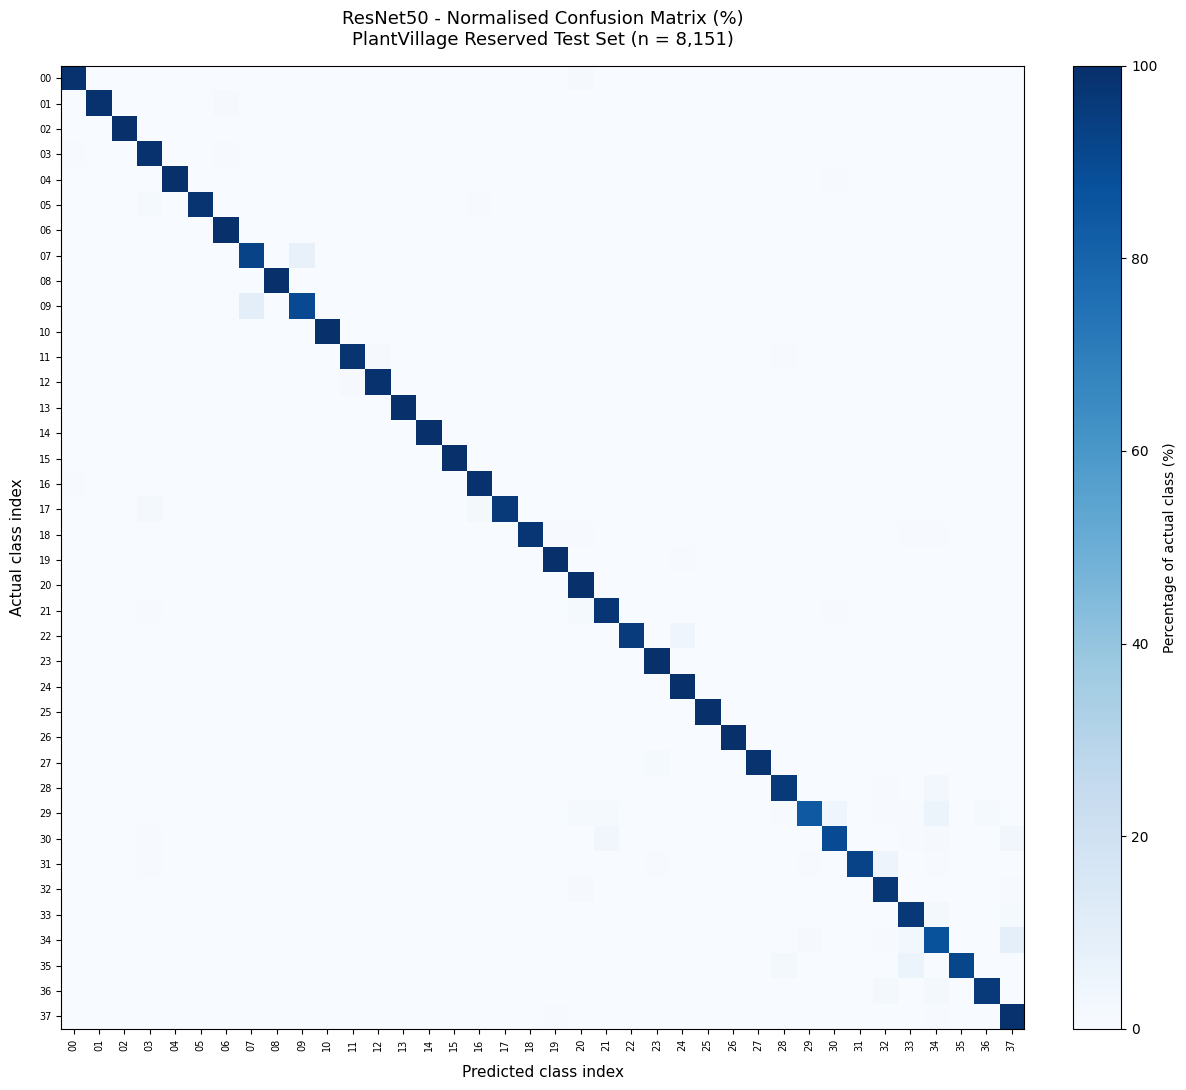


TOP FIVE MISCLASSIFICATION PATTERNS


,Actual class,Predicted as,Images,% of actual class
0,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Spider_mites Two-spotted_spider_mite,48,5.97
1,Tomato___Target_Spot,Tomato___healthy,19,9.00
2,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,15,10.14
3,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Bacterial_spot,14,1.74
4,Tomato___Late_blight,Potato___Late_blight,10,3.51



Matrix CSV files: SAVED
Matrix PNG files: SAVED

-----------------------------------------------------------------
MODEL: MobileNetV2
-----------------------------------------------------------------

CONFUSION MATRIX INTEGRITY
Matrix shape: (38, 38)
Total images: 8151
Correct classifications: 7893
Incorrect classifications: 258
Agreement with Cell 9: VERIFIED


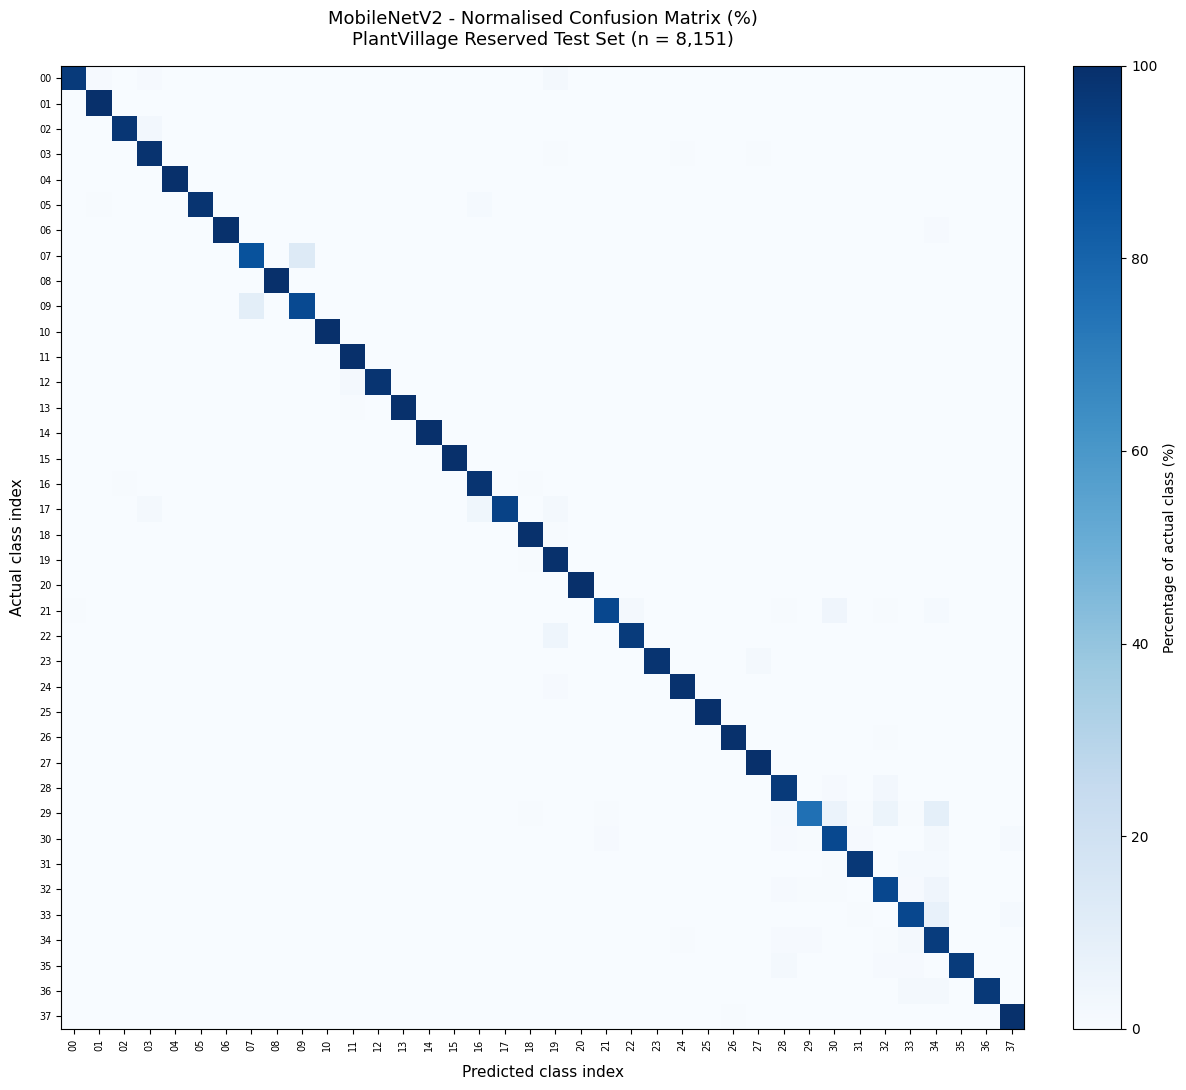


TOP FIVE MISCLASSIFICATION PATTERNS


,Actual class,Predicted as,Images,% of actual class
0,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,19,7.54
1,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,15,10.14
2,Tomato___Early_blight,Tomato___Target_Spot,14,9.33
3,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Bacterial_spot,13,1.62
4,Tomato___Septoria_leaf_spot,Tomato___Target_Spot,11,4.14



Matrix CSV files: SAVED
Matrix PNG files: SAVED

-----------------------------------------------------------------
MODEL: EfficientNetB0
-----------------------------------------------------------------

CONFUSION MATRIX INTEGRITY
Matrix shape: (38, 38)
Total images: 8151
Correct classifications: 8030
Incorrect classifications: 121
Agreement with Cell 9: VERIFIED


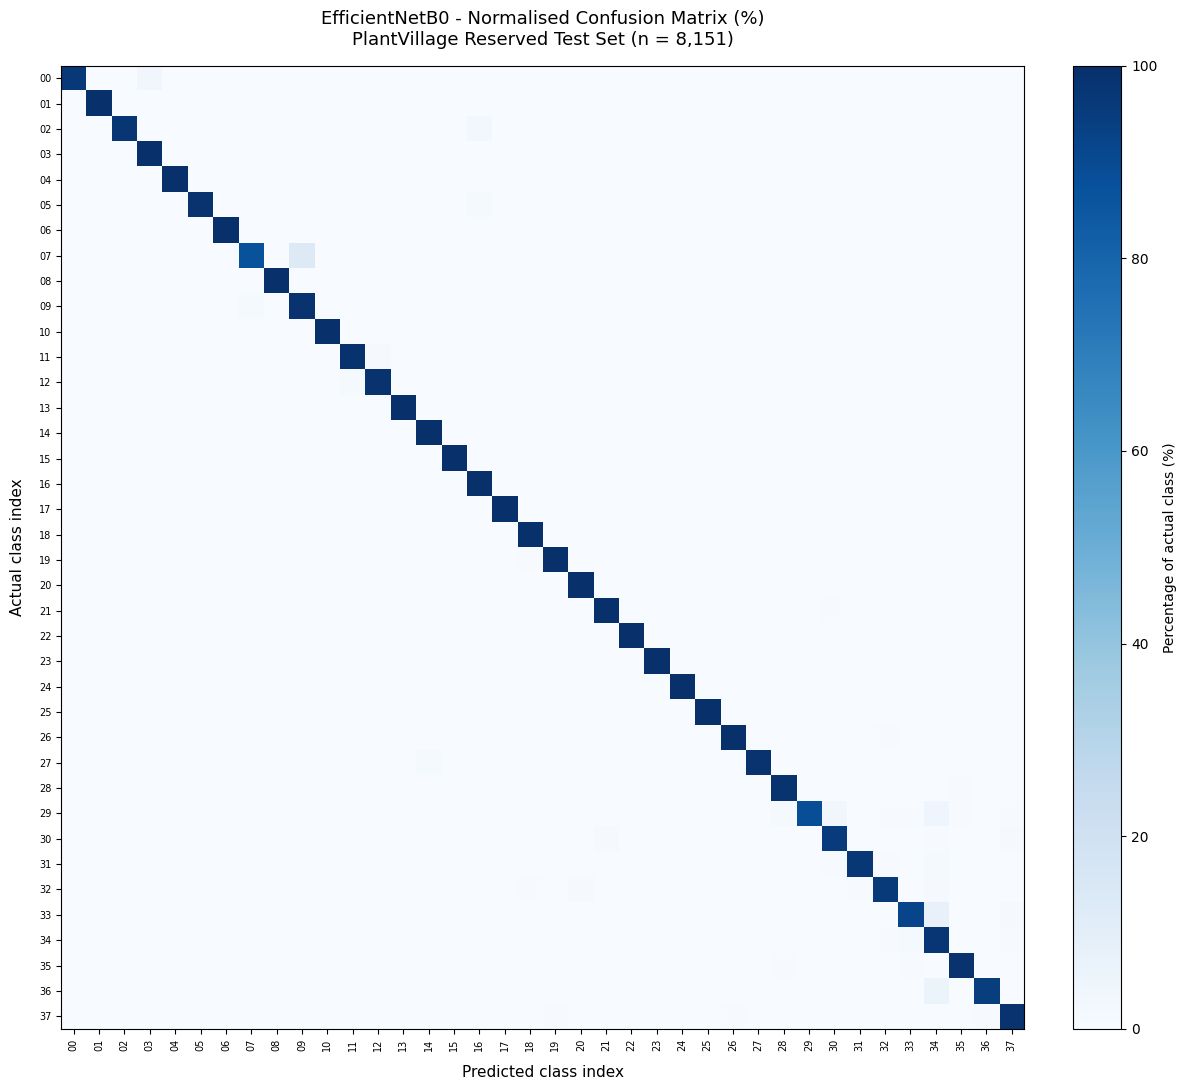


TOP FIVE MISCLASSIFICATION PATTERNS


,Actual class,Predicted as,Images,% of actual class
0,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,18,7.14
1,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,Corn_(maize)___Northern_Leaf_Blight,10,12.99
2,Tomato___Early_blight,Tomato___Target_Spot,6,4.00
3,Tomato___Early_blight,Tomato___Late_blight,5,3.33
4,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Bacterial_spot,5,0.62



Matrix CSV files: SAVED
Matrix PNG files: SAVED

CONFUSION MATRIX SUMMARY


,model,total_test_images,correct_predictions,incorrect_predictions,distinct_error_pairs
0,ResNet50,8151,7902,249,76
1,MobileNetV2,8151,7893,258,87
2,EfficientNetB0,8151,8030,121,53



PHASE 6.3 - CONFUSION MATRICES COMPLETED
Models analysed: 3
Classes per model: 38
Raw confusion matrix CSV files: 3
Normalised matrix CSV files: 3
Confusion matrix PNG files: 6
Consolidated error pair file: SAVED

Misclassification analysis:
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/plantvillage_test/plantvillage_misclassification_pairs.csv

Additional model inference performed: NO
Model retraining performed: NO


In [12]:

# ============================================================
# PHASE 6.3 - CELL 11
# Generate confusion matrices and identify error patterns
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

print("=" * 65)
print("PHASE 6.3 - CONFUSION MATRIX ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Verify the original PlantVillage class mapping
# ------------------------------------------------------------

class_indices = np.arange(NUM_CLASSES)

assert len(class_names) == NUM_CLASSES == 38

assert np.array_equal(
    np.unique(test_labels),
    class_indices
)

class_reference_df = pd.DataFrame({
    "class_index": class_indices,
    "class_name": class_names
})

class_reference_path = (
    CONTROLLED_DIR
    / "plantvillage_class_index_reference.csv"
)

class_reference_df.to_csv(
    class_reference_path,
    index=False
)

print("\nClass mapping: VERIFIED")
print("Total classes:", NUM_CLASSES)
print("Class reference:", class_reference_path)

# ------------------------------------------------------------
# 2. Define a reusable confusion matrix plotting function
# ------------------------------------------------------------

def plot_confusion_matrix(
    matrix,
    model_name,
    title_type,
    output_path,
    normalised=False,
    display_plot=True
):

    fig, ax = plt.subplots(figsize=(13, 11))

    image = ax.imshow(
        matrix,
        interpolation="nearest",
        cmap="Blues",
        vmin=0,
        vmax=100 if normalised else None
    )

    colourbar = fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    colourbar.set_label(
        "Percentage of actual class (%)"
        if normalised
        else "Number of images"
    )

    ax.set_title(
        f"{model_name} - {title_type}\n"
        "PlantVillage Reserved Test Set (n = 8,151)",
        fontsize=13,
        pad=15
    )

    tick_positions = np.arange(NUM_CLASSES)

    tick_labels = [
        f"{index:02d}"
        for index in tick_positions
    ]

    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)

    ax.set_xticklabels(
        tick_labels,
        fontsize=7,
        rotation=90
    )

    ax.set_yticklabels(
        tick_labels,
        fontsize=7
    )

    ax.set_xlabel(
        "Predicted class index",
        fontsize=11,
        labelpad=10
    )

    ax.set_ylabel(
        "Actual class index",
        fontsize=11,
        labelpad=10
    )

    fig.tight_layout()

    fig.savefig(
        output_path,
        dpi=220,
        bbox_inches="tight"
    )

    if display_plot:
        plt.show()

    plt.close(fig)


# ------------------------------------------------------------
# 3. Generate matrices for each evaluated model
# ------------------------------------------------------------

all_confusion_pairs = []
confusion_summary = []

for model_name in MODEL_NAMES:

    print("\n" + "-" * 65)
    print(f"MODEL: {model_name}")
    print("-" * 65)

    prediction_path = (
        CONTROLLED_DIR
        / f"{model_name}_test_predictions.npz"
    )

    with np.load(
        prediction_path,
        allow_pickle=False
    ) as saved:

        y_true = saved["true_labels"].copy()
        y_pred = saved["predicted_labels"].copy()

    assert np.array_equal(
        y_true,
        test_labels
    )

    assert len(y_pred) == 8151

    # --------------------------------------------------------
    # 4. Calculate the raw confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_indices
    )

    assert cm.shape == (38, 38)

    assert cm.sum() == 8151

    class_support = np.bincount(
        y_true,
        minlength=NUM_CLASSES
    )

    np.testing.assert_array_equal(
        cm.sum(axis=1),
        class_support
    )

    correct = int(np.trace(cm))
    incorrect = int(cm.sum() - correct)

    assert correct == int(
        np.sum(y_true == y_pred)
    )

    # Compare with Cell 9 metrics
    previous_record = metrics_df.loc[
        metrics_df["model"] == model_name
    ]

    assert len(previous_record) == 1

    assert correct == int(
        previous_record.iloc[0]["correct_predictions"]
    )

    assert incorrect == int(
        previous_record.iloc[0]["incorrect_predictions"]
    )

    print("\nCONFUSION MATRIX INTEGRITY")
    print("Matrix shape:", cm.shape)
    print("Total images:", int(cm.sum()))
    print("Correct classifications:", correct)
    print("Incorrect classifications:", incorrect)
    print("Agreement with Cell 9: VERIFIED")

    # --------------------------------------------------------
    # 5. Calculate row-normalised confusion matrix
    # --------------------------------------------------------

    assert np.all(class_support > 0)

    cm_normalised = (
        cm / class_support[:, np.newaxis]
    ) * 100

    assert np.allclose(
        cm_normalised.sum(axis=1),
        100,
        atol=1e-8
    )

    # --------------------------------------------------------
    # 6. Save both matrices as CSV
    # --------------------------------------------------------

    counts_path = (
        CONTROLLED_DIR
        / f"{model_name}_confusion_matrix_counts.csv"
    )

    normalised_path = (
        CONTROLLED_DIR
        / f"{model_name}_confusion_matrix_normalised.csv"
    )

    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    ).to_csv(
        counts_path,
        index_label="Actual class"
    )

    pd.DataFrame(
        cm_normalised,
        index=class_names,
        columns=class_names
    ).to_csv(
        normalised_path,
        index_label="Actual class",
        float_format="%.6f"
    )

    # --------------------------------------------------------
    # 7. Generate and save visual confusion matrices
    # --------------------------------------------------------

    counts_image_path = (
        CONTROLLED_DIR
        / f"{model_name}_confusion_matrix_counts.png"
    )

    normalised_image_path = (
        CONTROLLED_DIR
        / f"{model_name}_confusion_matrix_normalised.png"
    )

    # Save raw counts without displaying another large plot.
    plot_confusion_matrix(
        cm,
        model_name,
        "Confusion Matrix (Counts)",
        counts_image_path,
        normalised=False,
        display_plot=False
    )

    # Display the row-normalised matrix.
    plot_confusion_matrix(
        cm_normalised,
        model_name,
        "Normalised Confusion Matrix (%)",
        normalised_image_path,
        normalised=True,
        display_plot=True
    )

    # --------------------------------------------------------
    # 8. Identify the most frequent misclassifications
    # --------------------------------------------------------

    error_matrix = cm.copy()

    # Exclude correct predictions on the diagonal.
    np.fill_diagonal(error_matrix, 0)

    error_indices = np.argwhere(error_matrix > 0)

    confusion_pairs = []

    for actual_idx, predicted_idx in error_indices:

        count = int(
            error_matrix[actual_idx, predicted_idx]
        )

        confusion_pairs.append({
            "model": model_name,
            "actual_class_index": int(actual_idx),
            "actual_class": class_names[actual_idx],
            "predicted_class_index": int(predicted_idx),
            "predicted_class": class_names[predicted_idx],
            "error_count": count,
            "actual_class_support": int(
                class_support[actual_idx]
            ),
            "actual_class_error_percentage": (
                count / class_support[actual_idx] * 100
            )
        })

    model_pairs_df = pd.DataFrame(confusion_pairs)

    model_pairs_df = model_pairs_df.sort_values(
        [
            "error_count",
            "actual_class_index",
            "predicted_class_index"
        ],
        ascending=[False, True, True]
    ).reset_index(drop=True)

    all_confusion_pairs.append(model_pairs_df)

    print("\nTOP FIVE MISCLASSIFICATION PATTERNS")

    top_five = model_pairs_df.head(5).copy()

    top_five["actual_class_error_percentage"] = (
        top_five["actual_class_error_percentage"]
        .round(2)
    )

    with pd.option_context(
        "display.max_colwidth", None,
        "display.max_columns", None
    ):
        display(
            top_five[
                [
                    "actual_class",
                    "predicted_class",
                    "error_count",
                    "actual_class_error_percentage"
                ]
            ].rename(columns={
                "actual_class": "Actual class",
                "predicted_class": "Predicted as",
                "error_count": "Images",
                "actual_class_error_percentage":
                    "% of actual class"
            })
        )

    confusion_summary.append({
        "model": model_name,
        "total_test_images": int(cm.sum()),
        "correct_predictions": correct,
        "incorrect_predictions": incorrect,
        "distinct_error_pairs": len(model_pairs_df)
    })

    print("\nMatrix CSV files: SAVED")
    print("Matrix PNG files: SAVED")

# ------------------------------------------------------------
# 9. Save consolidated misclassification results
# ------------------------------------------------------------

all_confusion_pairs_df = pd.concat(
    all_confusion_pairs,
    ignore_index=True
)

error_pairs_path = (
    CONTROLLED_DIR
    / "plantvillage_misclassification_pairs.csv"
)

all_confusion_pairs_df.to_csv(
    error_pairs_path,
    index=False,
    float_format="%.6f"
)

confusion_summary_df = pd.DataFrame(
    confusion_summary
)

print("\n" + "=" * 65)
print("CONFUSION MATRIX SUMMARY")
print("=" * 65)

display(confusion_summary_df)

print("\n" + "=" * 65)
print("PHASE 6.3 - CONFUSION MATRICES COMPLETED")
print("=" * 65)

print("Models analysed: 3")
print("Classes per model: 38")
print("Raw confusion matrix CSV files: 3")
print("Normalised matrix CSV files: 3")
print("Confusion matrix PNG files: 6")
print("Consolidated error pair file: SAVED")

print("\nMisclassification analysis:")
print(error_pairs_path)

print("\nAdditional model inference performed: NO")
print("Model retraining performed: NO")
print("=" * 65)


EfficientNetB0 has 128 fewer incorrect predictions than ResNet50 and 137 fewer than MobileNetV2. Its mistakes are also distributed across fewer actual-to-predicted class combinations.

Important misclassification findings
Three patterns are particularly relevant to AgroVision.
- Tomato Spider Mites vs Tomato Target Spot: EfficientNetB0 misclassified 18 Spider Mites images as Target Spot, representing 7.14% of the actual Spider Mites samples. MobileNetV2 made 19 errors in the same direction.
- Corn Cercospora Leaf Spot vs Northern Leaf Blight: EfficientNetB0 misclassified 10 of 77 Cercospora images as Northern Leaf Blight (12.99%). This is a notable weakness despite its excellent overall accuracy.
- Tomato Early Blight: MobileNetV2 misclassified 14 Early Blight images as Target Spot, while EfficientNetB0 made six errors in that direction.
ResNet50 also produced 48 instances of Tomato Yellow Leaf Curl Virus being predicted as Spider Mites, its most frequent individual error pattern.
What these results mean
EfficientNetB0 remains the strongest model on the controlled PlantVillage test set, but its performance is not uniform across diseases.

In [13]:

# ============================================================
# PHASE 6.4 - CELL 12
# Restore and verify external evaluation datasets
# ============================================================

from pathlib import Path
import subprocess
import pandas as pd
import numpy as np

print("=" * 65)
print("PHASE 6.4 - EXTERNAL DATASET READINESS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Locate existing Phase 2 deliverables
# ------------------------------------------------------------

MAPPING_DIR = PROJECT_ROOT / "mapping_results"
PLANTDOC_DIR = PROJECT_ROOT / "plantdoc_preparation"
FIELDPLANT_DIR = PROJECT_ROOT / "fieldplant_preparation"
AUDIT_DIR = PROJECT_ROOT / "external_dataset_audit"

plantdoc_inventory_path = (
    PLANTDOC_DIR / "plantdoc_test_inventory.csv"
)

fieldplant_inventory_path = (
    FIELDPLANT_DIR / "fieldplant_crop_inventory.csv"
)

required_files = [
    plantdoc_inventory_path,
    fieldplant_inventory_path,
    MAPPING_DIR / "plantdoc_final_mapping.csv",
    MAPPING_DIR / "fieldplant_approved_mapping.csv",
    AUDIT_DIR / "plantdoc_exact_overlap.csv",
    AUDIT_DIR / "fieldplant_exact_overlap.csv"
]

missing_files = [
    str(path)
    for path in required_files
    if not path.is_file()
]

assert not missing_files, (
    "Missing Phase 2 deliverables:\n"
    + "\n".join(missing_files)
)

print("\nPhase 2 preparation files: VERIFIED")

# ------------------------------------------------------------
# 2. Restore PlantDoc source only if missing
# ------------------------------------------------------------

plantdoc_root = Path("/content/PlantDoc-Dataset")

if plantdoc_root.is_dir():
    print("\nPlantDoc repository: ALREADY AVAILABLE")
else:
    assert not plantdoc_root.exists(), (
        "PlantDoc path exists but is not a directory."
    )

    print("\nPlantDoc repository not found.")
    print("Restoring original Phase 2 source...")

    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/pratikkayal/PlantDoc-Dataset.git",
            str(plantdoc_root)
        ],
        check=True
    )

    print("PlantDoc repository: RESTORED")

# ------------------------------------------------------------
# 3. Load saved external image inventories
# ------------------------------------------------------------

plantdoc_eval_df = pd.read_csv(
    plantdoc_inventory_path
)

fieldplant_eval_df = pd.read_csv(
    fieldplant_inventory_path
)

assert len(plantdoc_eval_df) == 236
assert len(fieldplant_eval_df) == 504

assert plantdoc_eval_df["filepath"].is_unique
assert fieldplant_eval_df["crop_filepath"].is_unique

# Preserve a deterministic evaluation order
plantdoc_eval_df = (
    plantdoc_eval_df
    .sort_values("filepath")
    .reset_index(drop=True)
)

fieldplant_eval_df = (
    fieldplant_eval_df
    .sort_values("crop_filepath")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Verify saved class mapping decisions
# ------------------------------------------------------------

plantdoc_mapping = pd.read_csv(
    MAPPING_DIR / "plantdoc_final_mapping.csv"
)

fieldplant_mapping = pd.read_csv(
    MAPPING_DIR / "fieldplant_approved_mapping.csv"
)

plantdoc_lookup = dict(
    zip(
        plantdoc_mapping["class_name"],
        plantdoc_mapping["plantvillage_class"]
    )
)

fieldplant_lookup = dict(
    zip(
        fieldplant_mapping["class_id"].astype(int),
        fieldplant_mapping["plantvillage_class"]
    )
)

assert all(
    plantdoc_lookup.get(row.plantdoc_class)
    == row.plantvillage_class
    for row in plantdoc_eval_df.itertuples()
)

assert all(
    fieldplant_lookup.get(int(row.fieldplant_class_id))
    == row.plantvillage_class
    for row in fieldplant_eval_df.itertuples()
)

for dataset_df in [
    plantdoc_eval_df,
    fieldplant_eval_df
]:
    assert dataset_df["plantvillage_class"].isin(
        class_to_index
    ).all()

    dataset_df["class_index"] = (
        dataset_df["plantvillage_class"]
        .map(class_to_index)
        .astype(np.int32)
    )

print("External class mappings: VERIFIED")

# ------------------------------------------------------------
# 5. Verify external image file availability
# ------------------------------------------------------------

plantdoc_missing = [
    path
    for path in plantdoc_eval_df["filepath"]
    if not Path(path).is_file()
]

fieldplant_missing = [
    path
    for path in fieldplant_eval_df["crop_filepath"]
    if not Path(path).is_file()
]

print("\nIMAGE FILE AVAILABILITY")

print(
    "PlantDoc available:",
    len(plantdoc_eval_df) - len(plantdoc_missing),
    "/", len(plantdoc_eval_df)
)

print(
    "FieldPlant available:",
    len(fieldplant_eval_df) - len(fieldplant_missing),
    "/", len(fieldplant_eval_df)
)

if plantdoc_missing:
    print("Example missing PlantDoc path:", plantdoc_missing[0])

if fieldplant_missing:
    print("Example missing FieldPlant path:", fieldplant_missing[0])

assert not plantdoc_missing, "PlantDoc image files missing."
assert not fieldplant_missing, "FieldPlant crop files missing."

# ------------------------------------------------------------
# 6. Verify previously saved exact-overlap audit
# ------------------------------------------------------------

plantdoc_overlap = pd.read_csv(
    AUDIT_DIR / "plantdoc_exact_overlap.csv"
)

fieldplant_overlap = pd.read_csv(
    AUDIT_DIR / "fieldplant_exact_overlap.csv"
)

assert len(plantdoc_overlap) == 0
assert len(fieldplant_overlap) == 0

print("\nPREVIOUS CROSS-DATASET AUDIT")
print("PlantDoc exact overlaps:", len(plantdoc_overlap))
print("FieldPlant exact overlaps:", len(fieldplant_overlap))
print("Saved Phase 2 audit: VERIFIED")

# ------------------------------------------------------------
# 7. Verify actual external class coverage
# ------------------------------------------------------------

plantdoc_classes = set(
    plantdoc_eval_df["plantvillage_class"]
)

fieldplant_classes = set(
    fieldplant_eval_df["plantvillage_class"]
)

external_classes = (
    plantdoc_classes | fieldplant_classes
)

fieldplant_source_count = (
    fieldplant_eval_df["source_image_filepath"]
    .nunique()
)

assert len(plantdoc_classes) == 27
assert len(fieldplant_classes) == 4
assert len(external_classes) == 28
assert fieldplant_source_count == 289

print("\nEXTERNAL DATASET SUMMARY")

summary_df = pd.DataFrame([
    {
        "Dataset": "Cropped-PlantDoc",
        "Samples": len(plantdoc_eval_df),
        "Classes": len(plantdoc_classes)
    },
    {
        "Dataset": "Cropped-FieldPlant",
        "Samples": len(fieldplant_eval_df),
        "Classes": len(fieldplant_classes)
    }
])

display(summary_df)

print("Unique external classes:", len(external_classes))
print("Unrepresented PlantVillage classes:",
      NUM_CLASSES - len(external_classes))
print("FieldPlant source photographs:",
      fieldplant_source_count)

# ------------------------------------------------------------
# 8. Create evaluation output directory
# ------------------------------------------------------------

EXTERNAL_EVAL_DIR = (
    PHASE6_DIR / "external_evaluation"
)

EXTERNAL_EVAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\n" + "=" * 65)
print("EXTERNAL DATASET READINESS: PASSED")
print("=" * 65)

print("PlantDoc test inventory: VERIFIED")
print("FieldPlant crop inventory: VERIFIED")
print("Approved class mappings: VERIFIED")
print("All external image files accessible: YES")
print("Previous overlap audit: VERIFIED")
print("External images evaluated: 0")
print("Model predictions performed: 0")
print("Model retraining performed: NO")

print("\nOutput directory:")
print(EXTERNAL_EVAL_DIR)

print("=" * 65)


PHASE 6.4 - EXTERNAL DATASET READINESS

Phase 2 preparation files: VERIFIED

PlantDoc repository not found.
Restoring original Phase 2 source...
PlantDoc repository: RESTORED
External class mappings: VERIFIED

IMAGE FILE AVAILABILITY
PlantDoc available: 236 / 236
FieldPlant available: 504 / 504

PREVIOUS CROSS-DATASET AUDIT
PlantDoc exact overlaps: 0
FieldPlant exact overlaps: 0
Saved Phase 2 audit: VERIFIED

EXTERNAL DATASET SUMMARY


,Dataset,Samples,Classes
0,Cropped-PlantDoc,236,27
1,Cropped-FieldPlant,504,4


Unique external classes: 28
Unrepresented PlantVillage classes: 10
FieldPlant source photographs: 289

EXTERNAL DATASET READINESS: PASSED
PlantDoc test inventory: VERIFIED
FieldPlant crop inventory: VERIFIED
Approved class mappings: VERIFIED
All external image files accessible: YES
Previous overlap audit: VERIFIED
External images evaluated: 0
Model predictions performed: 0
Model retraining performed: NO

Output directory:
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/external_evaluation


In [14]:

# ============================================================
# PHASE 6.4 - CELL 13
# External inference: Cropped-PlantDoc and Cropped-FieldPlant
# ============================================================

import numpy as np
import tensorflow as tf
import gc
import math
from pathlib import Path

print("=" * 65)
print("PHASE 6.4 - EXTERNAL DATASET INFERENCE")
print("=" * 65)

# ------------------------------------------------------------
# 1. Reuse the approved Phase 2 inventories
# ------------------------------------------------------------

external_sources = {
    "PlantDoc": {
        "frame": plantdoc_eval_df,
        "path_column": "filepath",
        "expected_samples": 236,
        "expected_classes": 27
    },
    "FieldPlant": {
        "frame": fieldplant_eval_df,
        "path_column": "crop_filepath",
        "expected_samples": 504,
        "expected_classes": 4
    }
}

external_datasets = {}

# ------------------------------------------------------------
# 2. Construct deterministic external evaluation datasets
# ------------------------------------------------------------

for dataset_name, config in external_sources.items():

    frame = config["frame"]

    filepaths = np.asarray(
        frame[config["path_column"]].astype(str).tolist(),
        dtype=np.str_
    )

    if dataset_name == "FieldPlant":
        source_paths = np.asarray(
            frame["source_image_filepath"].astype(str).tolist(),
            dtype=np.str_
        )
    else:
        source_paths = filepaths.copy()

    true_classes = np.asarray(
        frame["plantvillage_class"].astype(str).tolist(),
        dtype=np.str_
    )

    true_labels = frame["class_index"].to_numpy(
        dtype=np.int32
    )

    assert len(filepaths) == config["expected_samples"]
    assert len(np.unique(true_labels)) == config["expected_classes"]
    assert len(np.unique(filepaths)) == len(filepaths)

    assert np.array_equal(
        true_labels,
        np.asarray(
            [class_to_index[name] for name in true_classes],
            dtype=np.int32
        )
    )

    assert np.all(
        (true_labels >= 0) & (true_labels < NUM_CLASSES)
    )

    # Verify decoding using one actual external image.
    probe_image, _ = load_evaluation_image(
        tf.constant(filepaths[0]),
        tf.constant(true_labels[0])
    )

    assert tuple(probe_image.shape) == (160, 160, 3)
    assert probe_image.dtype == tf.float32
    assert bool(
        tf.reduce_all(tf.math.is_finite(probe_image)).numpy()
    )

    assert float(tf.reduce_min(probe_image)) >= 0
    assert float(tf.reduce_max(probe_image)) <= 255

    # Use the exact preprocessing function from Cell 7.
    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, true_labels)
    )

    dataset = dataset.map(
        load_evaluation_image,
        num_parallel_calls=2,
        deterministic=True
    )

    dataset = dataset.batch(EVAL_BATCH_SIZE).prefetch(1)

    expected_batches = math.ceil(
        len(filepaths) / EVAL_BATCH_SIZE
    )

    assert int(
        tf.data.experimental.cardinality(dataset).numpy()
    ) == expected_batches

    external_datasets[dataset_name] = {
        "dataset": dataset,
        "filepaths": filepaths,
        "source_paths": source_paths,
        "true_classes": true_classes,
        "true_labels": true_labels
    }

    print(f"\n{dataset_name.upper()}")
    print("Samples:", len(filepaths))
    print("Classes:", len(np.unique(true_labels)))
    print("Batches:", expected_batches)
    print("Image decoding: VERIFIED")

print("\nExternal dataset pipelines: PREPARED")

# ------------------------------------------------------------
# 3. Define saved prediction verification
# ------------------------------------------------------------

def verify_external_predictions(path, data):

    expected_count = len(data["true_labels"])

    with np.load(path, allow_pickle=False) as saved:

        probabilities = saved["probabilities"]
        predicted = saved["predicted_labels"]

        assert probabilities.shape == (
            expected_count, NUM_CLASSES
        )

        assert predicted.shape == (expected_count,)

        assert np.array_equal(
            saved["true_labels"],
            data["true_labels"]
        )

        assert np.array_equal(
            saved["true_classes"],
            data["true_classes"]
        )

        assert np.array_equal(
            saved["filepaths"],
            data["filepaths"]
        )

        assert np.array_equal(
            saved["source_image_filepaths"],
            data["source_paths"]
        )

        assert np.isfinite(probabilities).all()

        assert np.all(
            (probabilities >= 0) &
            (probabilities <= 1)
        )

        assert np.allclose(
            probabilities.sum(axis=1),
            1.0,
            atol=1e-3,
            rtol=0
        )

        assert np.array_equal(
            predicted,
            np.argmax(probabilities, axis=1)
        )

    return True


# ------------------------------------------------------------
# 4. Run all three models across both external datasets
# ------------------------------------------------------------

external_inference_results = {}

for model_name in MODEL_NAMES:

    print("\n" + "-" * 65)
    print(f"MODEL: {model_name}")
    print("-" * 65)

    checkpoint_path = (
        EXPERIMENT_DIR
        / model_name
        / "stage2"
        / "best_model.keras"
    )

    assert checkpoint_path.is_file()

    pending_datasets = []

    for dataset_name, data in external_datasets.items():

        result_path = (
            EXTERNAL_EVAL_DIR
            / f"{model_name}_{dataset_name}_predictions.npz"
        )

        partial_path = (
            EXTERNAL_EVAL_DIR
            / f"{model_name}_{dataset_name}_predictions.partial.npz"
        )

        # Reuse previously verified predictions.
        if result_path.exists():

            verify_external_predictions(
                result_path,
                data
            )

            print(f"{dataset_name}: Existing predictions VERIFIED")

            external_inference_results[
                (model_name, dataset_name)
            ] = str(result_path)

            continue

        # Recover a complete temporary file if present.
        if partial_path.exists():

            verify_external_predictions(
                partial_path,
                data
            )

            partial_path.replace(result_path)

            print(f"{dataset_name}: Saved predictions RECOVERED")

            external_inference_results[
                (model_name, dataset_name)
            ] = str(result_path)

            continue

        pending_datasets.append(dataset_name)

    # No unnecessary checkpoint loading.
    if not pending_datasets:
        print("No additional inference required.")
        continue

    tf.keras.backend.clear_session()
    gc.collect()

    print("\nLoading saved Stage 2 checkpoint...")

    model = tf.keras.models.load_model(
        str(checkpoint_path),
        compile=False,
        safe_mode=True
    )

    assert tuple(model.input_shape) == (
        None, 160, 160, 3
    )

    assert tuple(model.output_shape) == (
        None, NUM_CLASSES
    )

    print("Checkpoint loaded successfully.")

    # --------------------------------------------------------
    # 5. Predict each external dataset separately
    # --------------------------------------------------------

    for dataset_name in pending_datasets:

        data = external_datasets[dataset_name]

        result_path = (
            EXTERNAL_EVAL_DIR
            / f"{model_name}_{dataset_name}_predictions.npz"
        )

        partial_path = (
            EXTERNAL_EVAL_DIR
            / f"{model_name}_{dataset_name}_predictions.partial.npz"
        )

        print(f"\nEvaluating {dataset_name}...")
        print("Images:", len(data["true_labels"]))

        probabilities = model.predict(
            data["dataset"],
            verbose=1
        )

        probabilities = np.asarray(
            probabilities,
            dtype=np.float32
        )

        predicted_labels = np.argmax(
            probabilities,
            axis=1
        ).astype(np.int32)

        assert probabilities.shape == (
            len(data["true_labels"]),
            NUM_CLASSES
        )

        assert np.isfinite(probabilities).all()

        assert np.all(
            (probabilities >= 0) &
            (probabilities <= 1)
        )

        assert np.allclose(
            probabilities.sum(axis=1),
            1.0,
            atol=1e-3,
            rtol=0
        )

        # ----------------------------------------------------
        # 6. Save predictions and original sample provenance
        # ----------------------------------------------------

        np.savez_compressed(
            partial_path,
            true_labels=data["true_labels"],
            true_classes=data["true_classes"],
            predicted_labels=predicted_labels,
            probabilities=probabilities,
            filepaths=data["filepaths"],
            source_image_filepaths=data["source_paths"]
        )

        # Verify before finalising.
        verify_external_predictions(
            partial_path,
            data
        )

        partial_path.replace(result_path)

        print("Prediction integrity: PASSED")
        print("Prediction shape:", probabilities.shape)
        print("Saved to:", result_path)

        external_inference_results[
            (model_name, dataset_name)
        ] = str(result_path)

        del probabilities
        del predicted_labels

    # --------------------------------------------------------
    # 7. Release model memory
    # --------------------------------------------------------

    del model

    tf.keras.backend.clear_session()
    gc.collect()

    print("\nModel memory released.")

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------

assert len(external_inference_results) == 6

for (model_name, dataset_name), result_path in (
    external_inference_results.items()
):

    assert Path(result_path).is_file()

    verify_external_predictions(
        result_path,
        external_datasets[dataset_name]
    )

print("\n" + "=" * 65)
print("PHASE 6.4 - EXTERNAL INFERENCE COMPLETED")
print("=" * 65)

print("\nModels evaluated:", len(MODEL_NAMES))
print("External datasets:", len(external_datasets))
print("Prediction files verified:", len(external_inference_results))

print("\nSamples per model:")
print("Cropped-PlantDoc: 236")
print("Cropped-FieldPlant: 504")
print("Combined: 740")

print("\nModel output classes: 38")
print("Model retraining performed: NO")
print("Source datasets modified: NO")
print("External performance metrics calculated: NO")

print("\nResults directory:")
print(EXTERNAL_EVAL_DIR)

print("\nReady for external performance metrics.")
print("=" * 65)


PHASE 6.4 - EXTERNAL DATASET INFERENCE

PLANTDOC
Samples: 236
Classes: 27
Batches: 8
Image decoding: VERIFIED

FIELDPLANT
Samples: 504
Classes: 4
Batches: 16
Image decoding: VERIFIED

External dataset pipelines: PREPARED

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------

Loading saved Stage 2 checkpoint...
Checkpoint loaded successfully.

Evaluating PlantDoc...
Images: 236
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 398ms/step
Prediction integrity: PASSED
Prediction shape: (236, 38)
Saved to: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/external_evaluation/ResNet50_PlantDoc_predictions.npz

Evaluating FieldPlant...
Images: 504
16/16 ━━━━━━━━━━━━━━━━━━━━ 293s 18s/step
Prediction integrity: PASSED
Prediction shape: (504, 38)
Saved to: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/external_evaluation/ResNet50_FieldPlant_predictions.npz

Model memory released.

--------------------------

In [15]:

# ============================================================
# PHASE 6.4 - CELL 14
# Calculate external dataset classification performance
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

print("=" * 65)
print("PHASE 6.4 - EXTERNAL DATASET PERFORMANCE METRICS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Define external evaluation configuration
# ------------------------------------------------------------

DATASET_DISPLAY_NAMES = {
    "PlantDoc": "Cropped-PlantDoc",
    "FieldPlant": "Cropped-FieldPlant"
}

external_metrics_records = []

# ------------------------------------------------------------
# 2. Evaluate the saved prediction files
# ------------------------------------------------------------

for dataset_name, data in external_datasets.items():

    print("\n" + "=" * 65)
    print(f"DATASET: {DATASET_DISPLAY_NAMES[dataset_name]}")
    print("=" * 65)

    expected_labels = data["true_labels"]
    expected_paths = data["filepaths"]
    expected_classes = data["true_classes"]
    expected_sources = data["source_paths"]

    represented_classes = np.unique(expected_labels)

    print("Images:", len(expected_labels))
    print("Represented classes:", len(represented_classes))
    print("Model output classes:", NUM_CLASSES)

    for model_name in MODEL_NAMES:

        print("\n" + "-" * 65)
        print(f"MODEL: {model_name}")
        print("-" * 65)

        prediction_path = (
            EXTERNAL_EVAL_DIR
            / f"{model_name}_{dataset_name}_predictions.npz"
        )

        assert prediction_path.is_file(), (
            f"Missing prediction file: {prediction_path}"
        )

        with np.load(
            prediction_path,
            allow_pickle=False
        ) as saved:

            y_true = saved["true_labels"].copy()
            y_pred = saved["predicted_labels"].copy()
            probabilities = saved["probabilities"].copy()

            saved_paths = saved["filepaths"].copy()
            saved_classes = saved["true_classes"].copy()
            saved_sources = (
                saved["source_image_filepaths"].copy()
            )

        # ----------------------------------------------------
        # 3. Verify sample and prediction integrity
        # ----------------------------------------------------

        assert np.array_equal(
            y_true,
            expected_labels
        ), "Ground-truth labels do not match."

        assert np.array_equal(
            saved_paths,
            expected_paths
        ), "External sample order mismatch."

        assert np.array_equal(
            saved_classes,
            expected_classes
        ), "Class mapping mismatch."

        assert np.array_equal(
            saved_sources,
            expected_sources
        ), "Source photograph mismatch."

        assert probabilities.shape == (
            len(y_true), NUM_CLASSES
        )

        assert np.isfinite(probabilities).all()

        assert np.allclose(
            probabilities.sum(axis=1),
            1.0,
            atol=1e-3,
            rtol=0
        )

        assert np.array_equal(
            y_pred,
            np.argmax(probabilities, axis=1)
        )

        assert np.all(
            (y_pred >= 0) & (y_pred < NUM_CLASSES)
        )

        print("Prediction integrity: VERIFIED")

        # ----------------------------------------------------
        # 4. Calculate overall accuracy
        # ----------------------------------------------------

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        correct = int(np.sum(y_true == y_pred))
        incorrect = int(np.sum(y_true != y_pred))

        assert correct + incorrect == len(y_true)

        # ----------------------------------------------------
        # 5. Calculate support-weighted metrics
        # ----------------------------------------------------

        weighted_precision, weighted_recall, (
            weighted_f1
        ), _ = precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=represented_classes,
            average="weighted",
            zero_division=0
        )

        # Weighted recall equals accuracy for this
        # single-label multiclass evaluation.
        assert np.isclose(
            accuracy,
            weighted_recall,
            atol=1e-12
        )

        # ----------------------------------------------------
        # 6. Calculate macro metrics
        # ----------------------------------------------------

        macro_precision, macro_recall, macro_f1, _ = (
            precision_recall_fscore_support(
                y_true,
                y_pred,
                labels=represented_classes,
                average="macro",
                zero_division=0
            )
        )

        # ----------------------------------------------------
        # 7. Identify predictions outside dataset coverage
        # ----------------------------------------------------

        # The model still predicts among all 38 classes.
        # Predictions outside the represented subset
        # are counted as incorrect, not discarded.

        outside_coverage = ~np.isin(
            y_pred,
            represented_classes
        )

        outside_count = int(
            np.sum(outside_coverage)
        )

        outside_percentage = (
            outside_count / len(y_true) * 100
        )

        assert outside_count <= incorrect

        # ----------------------------------------------------
        # 8. Store model evaluation results
        # ----------------------------------------------------

        external_metrics_records.append({
            "dataset": DATASET_DISPLAY_NAMES[dataset_name],
            "model": model_name,
            "test_images": len(y_true),
            "represented_classes": len(represented_classes),
            "correct_predictions": correct,
            "incorrect_predictions": incorrect,
            "accuracy": accuracy,
            "weighted_precision": weighted_precision,
            "weighted_recall": weighted_recall,
            "weighted_f1": weighted_f1,
            "macro_precision": macro_precision,
            "macro_recall": macro_recall,
            "macro_f1": macro_f1,
            "predictions_outside_coverage": outside_count,
            "outside_coverage_percentage": outside_percentage
        })

        print(f"Accuracy          : {accuracy * 100:.4f}%")
        print(
            f"Weighted precision: "
            f"{weighted_precision * 100:.4f}%"
        )
        print(
            f"Weighted recall   : "
            f"{weighted_recall * 100:.4f}%"
        )
        print(
            f"Weighted F1-score : "
            f"{weighted_f1 * 100:.4f}%"
        )
        print(
            f"Macro F1-score    : "
            f"{macro_f1 * 100:.4f}%"
        )

        print(f"\nCorrect predictions  : {correct:,}")
        print(f"Incorrect predictions: {incorrect:,}")

        print(
            "Predictions outside represented classes:",
            outside_count,
            f"({outside_percentage:.2f}%)"
        )

# ------------------------------------------------------------
# 9. Create consolidated comparison
# ------------------------------------------------------------

external_metrics_df = pd.DataFrame(
    external_metrics_records
)

assert len(external_metrics_df) == 6

assert set(external_metrics_df["model"]) == set(
    MODEL_NAMES
)

assert set(external_metrics_df["dataset"]) == set(
    DATASET_DISPLAY_NAMES.values()
)

comparison_columns = [
    "dataset",
    "model",
    "test_images",
    "represented_classes",
    "accuracy",
    "weighted_precision",
    "weighted_recall",
    "weighted_f1",
    "macro_f1"
]

external_comparison = external_metrics_df[
    comparison_columns
].copy()

percentage_columns = [
    "accuracy",
    "weighted_precision",
    "weighted_recall",
    "weighted_f1",
    "macro_f1"
]

external_comparison[percentage_columns] = (
    external_comparison[percentage_columns] * 100
).round(4)

external_comparison = external_comparison.rename(
    columns={
        "dataset": "Dataset",
        "model": "Model",
        "test_images": "Images",
        "represented_classes": "Classes",
        "accuracy": "Accuracy (%)",
        "weighted_precision": "Weighted Precision (%)",
        "weighted_recall": "Weighted Recall (%)",
        "weighted_f1": "Weighted F1 (%)",
        "macro_f1": "Macro F1 (%)"
    }
)

print("\n" + "=" * 65)
print("EXTERNAL DATASET PERFORMANCE COMPARISON")
print("=" * 65)

display(external_comparison)

# ------------------------------------------------------------
# 10. Save evaluation results
# ------------------------------------------------------------

external_metrics_path = (
    EXTERNAL_EVAL_DIR
    / "external_dataset_metrics.csv"
)

external_metrics_df.to_csv(
    external_metrics_path,
    index=False,
    float_format="%.12f"
)

assert external_metrics_path.is_file()

print("\nMetrics file: SAVED")
print("File location:", external_metrics_path)

# ------------------------------------------------------------
# 11. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PHASE 6.4 - EXTERNAL METRICS COMPLETED")
print("=" * 65)

print("Models evaluated: 3")
print("External datasets: 2")
print("Performance records: 6")
print("Results saved to Google Drive: YES")
print("Additional model inference: NO")
print("Model retraining: NO")
print("Original datasets modified: NO")

print("\nReady for Phase 6.5 generalisation analysis.")
print("=" * 65)


PHASE 6.4 - EXTERNAL DATASET PERFORMANCE METRICS

DATASET: Cropped-PlantDoc
Images: 236
Represented classes: 27
Model output classes: 38

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------
Prediction integrity: VERIFIED
Accuracy          : 17.7966%
Weighted precision: 24.2300%
Weighted recall   : 17.7966%
Weighted F1-score : 17.8556%
Macro F1-score    : 17.4497%

Correct predictions  : 42
Incorrect predictions: 194
Predictions outside represented classes: 69 (29.24%)

-----------------------------------------------------------------
MODEL: MobileNetV2
-----------------------------------------------------------------
Prediction integrity: VERIFIED
Accuracy          : 25.4237%
Weighted precision: 32.6500%
Weighted recall   : 25.4237%
Weighted F1-score : 24.3810%
Macro F1-score    : 24.3410%

Correct predictions  : 60
Incorrect predictions: 176
Predictions outside represented classes: 61 (25.8

,Dataset,Model,Images,Classes,Accuracy (%),Weighted Precision (%),Weighted Recall (%),Weighted F1 (%),Macro F1 (%)
0,Cropped-PlantDoc,ResNet50,236,27,17.7966,24.2300,17.7966,17.8556,17.4497
1,Cropped-PlantDoc,MobileNetV2,236,27,25.4237,32.6500,25.4237,24.3810,24.3410
2,Cropped-PlantDoc,EfficientNetB0,236,27,27.1186,32.0925,27.1186,25.5247,25.8554
3,Cropped-FieldPlant,ResNet50,504,4,29.9603,88.5768,29.9603,34.7025,38.5570
4,Cropped-FieldPlant,MobileNetV2,504,4,26.7857,83.0119,26.7857,27.5328,31.5935
5,Cropped-FieldPlant,EfficientNetB0,504,4,27.7778,92.2372,27.7778,34.5806,36.4242



Metrics file: SAVED
File location: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/external_evaluation/external_dataset_metrics.csv

PHASE 6.4 - EXTERNAL METRICS COMPLETED
Models evaluated: 3
External datasets: 2
Performance records: 6
Results saved to Google Drive: YES
Additional model inference: NO
Model retraining: NO
Original datasets modified: NO

Ready for Phase 6.5 generalisation analysis.


In [16]:
# ============================================================
# PHASE 6.5 - CELL 15
# Class-matched controlled vs external generalisation analysis
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("PHASE 6.5 - CLASS-MATCHED GENERALISATION ANALYSIS")
print("=" * 65)

comparison_records = []
per_class_records = []

# ------------------------------------------------------------
# 1. Compare each saved model across evaluation datasets
# ------------------------------------------------------------

for model_name in MODEL_NAMES:

    print("\n" + "-" * 65)
    print(f"MODEL: {model_name}")
    print("-" * 65)

    # Reuse the original PlantVillage test predictions.
    pv_prediction_path = (
        CONTROLLED_DIR
        / f"{model_name}_test_predictions.npz"
    )

    with np.load(
        pv_prediction_path,
        allow_pickle=False
    ) as saved:
        pv_true = saved["true_labels"].copy()
        pv_pred = saved["predicted_labels"].copy()

    assert np.array_equal(pv_true, test_labels)

    pv_correct = pv_true == pv_pred
    pv_full_accuracy = float(np.mean(pv_correct))

    # Calculate per-class PlantVillage accuracy.
    pv_support = np.bincount(
        pv_true,
        minlength=NUM_CLASSES
    )

    pv_correct_counts = np.bincount(
        pv_true[pv_correct],
        minlength=NUM_CLASSES
    )

    assert np.all(pv_support > 0)

    pv_class_accuracy = (
        pv_correct_counts / pv_support
    )

    # --------------------------------------------------------
    # 2. Analyse each external dataset separately
    # --------------------------------------------------------

    for dataset_name, data in external_datasets.items():

        prediction_path = (
            EXTERNAL_EVAL_DIR
            / f"{model_name}_{dataset_name}_predictions.npz"
        )

        with np.load(
            prediction_path,
            allow_pickle=False
        ) as saved:
            ext_true = saved["true_labels"].copy()
            ext_pred = saved["predicted_labels"].copy()

            assert np.array_equal(
                saved["filepaths"],
                data["filepaths"]
            )

        assert np.array_equal(
            ext_true,
            data["true_labels"]
        )

        represented = np.unique(ext_true)

        # Keep all 38 prediction outputs valid.
        pv_matched_mask = np.isin(
            pv_true,
            represented
        )

        # ----------------------------------------------------
        # 3. Calculate class-matched PlantVillage accuracy
        # ----------------------------------------------------

        pv_matched_accuracy = float(
            np.mean(pv_correct[pv_matched_mask])
        )

        pv_matched_samples = int(
            pv_matched_mask.sum()
        )

        # ----------------------------------------------------
        # 4. Adjust for external class distribution
        # ----------------------------------------------------

        ext_support = np.bincount(
            ext_true,
            minlength=NUM_CLASSES
        )

        ext_correct = ext_true == ext_pred

        ext_correct_counts = np.bincount(
            ext_true[ext_correct],
            minlength=NUM_CLASSES
        )

        ext_class_accuracy = np.divide(
            ext_correct_counts,
            ext_support,
            out=np.zeros(NUM_CLASSES, dtype=float),
            where=ext_support > 0
        )

        # Expected PlantVillage accuracy if its class-level
        # accuracies were weighted according to the external
        # dataset's class distribution.
        pv_adjusted_accuracy = float(
            np.average(
                pv_class_accuracy[represented],
                weights=ext_support[represented]
            )
        )

        external_accuracy = float(
            np.mean(ext_correct)
        )

        adjusted_gap_pp = (
            external_accuracy - pv_adjusted_accuracy
        ) * 100

        # ----------------------------------------------------
        # 5. Compare macro recall across represented classes
        # ----------------------------------------------------

        pv_macro_recall = float(
            np.mean(pv_class_accuracy[represented])
        )

        ext_macro_recall = float(
            np.mean(ext_class_accuracy[represented])
        )

        # ----------------------------------------------------
        # 6. Count predictions outside external class coverage
        # ----------------------------------------------------

        outside_coverage = ~np.isin(
            ext_pred,
            represented
        )

        outside_count = int(
            outside_coverage.sum()
        )

        outside_percentage = (
            outside_count / len(ext_true) * 100
        )

        # ----------------------------------------------------
        # 7. Store overall comparison
        # ----------------------------------------------------

        comparison_records.append({
            "model": model_name,
            "dataset": DATASET_DISPLAY_NAMES[dataset_name],
            "external_samples": len(ext_true),
            "represented_classes": len(represented),
            "matched_plantvillage_samples": pv_matched_samples,
            "plantvillage_full_accuracy_pct":
                pv_full_accuracy * 100,
            "plantvillage_matched_accuracy_pct":
                pv_matched_accuracy * 100,
            "plantvillage_adjusted_accuracy_pct":
                pv_adjusted_accuracy * 100,
            "external_accuracy_pct":
                external_accuracy * 100,
            "adjusted_gap_pp": adjusted_gap_pp,
            "plantvillage_matched_macro_recall_pct":
                pv_macro_recall * 100,
            "external_macro_recall_pct":
                ext_macro_recall * 100,
            "outside_coverage_count": outside_count,
            "outside_coverage_pct": outside_percentage
        })

        # ----------------------------------------------------
        # 8. Store individual class comparisons
        # ----------------------------------------------------

        for class_idx in represented:

            per_class_records.append({
                "model": model_name,
                "dataset": DATASET_DISPLAY_NAMES[dataset_name],
                "class_index": int(class_idx),
                "class_name": class_names[class_idx],
                "plantvillage_support":
                    int(pv_support[class_idx]),
                "external_support":
                    int(ext_support[class_idx]),
                "plantvillage_recall_pct":
                    pv_class_accuracy[class_idx] * 100,
                "external_recall_pct":
                    ext_class_accuracy[class_idx] * 100,
                "recall_gap_pp": (
                    ext_class_accuracy[class_idx]
                    - pv_class_accuracy[class_idx]
                ) * 100
            })

        print(
            f"\n{DATASET_DISPLAY_NAMES[dataset_name]}"
        )
        print("Represented classes:", len(represented))
        print("Matched PlantVillage images:", pv_matched_samples)

        print(
            f"PlantVillage matched accuracy: "
            f"{pv_matched_accuracy * 100:.2f}%"
        )

        print(
            f"PlantVillage adjusted accuracy: "
            f"{pv_adjusted_accuracy * 100:.2f}%"
        )

        print(
            f"External accuracy: "
            f"{external_accuracy * 100:.2f}%"
        )

        print(
            f"Adjusted gap: {adjusted_gap_pp:+.2f} pp"
        )

        print(
            f"Outside-coverage predictions: "
            f"{outside_count} ({outside_percentage:.2f}%)"
        )

# ------------------------------------------------------------
# 9. Create consolidated tables
# ------------------------------------------------------------

generalisation_df = pd.DataFrame(
    comparison_records
)

generalisation_class_df = pd.DataFrame(
    per_class_records
)

assert len(generalisation_df) == 6

assert len(generalisation_class_df) == (
    3 * (27 + 4)
)

print("\n" + "=" * 65)
print("CLASS-MATCHED GENERALISATION COMPARISON")
print("=" * 65)

display_columns = {
    "dataset": "Dataset",
    "model": "Model",
    "represented_classes": "Classes",
    "plantvillage_matched_accuracy_pct":
        "PV Matched (%)",
    "plantvillage_adjusted_accuracy_pct":
        "PV Adjusted (%)",
    "external_accuracy_pct":
        "External (%)",
    "adjusted_gap_pp": "Gap (pp)",
    "outside_coverage_pct":
        "Outside Coverage (%)"
}

comparison_display = generalisation_df[
    list(display_columns.keys())
].rename(columns=display_columns)

display(
    comparison_display.round(2)
)

# ------------------------------------------------------------
# 10. Save analysis results
# ------------------------------------------------------------

generalisation_path = (
    EXTERNAL_EVAL_DIR
    / "class_matched_generalisation_comparison.csv"
)

per_class_path = (
    EXTERNAL_EVAL_DIR
    / "external_per_class_generalisation.csv"
)

generalisation_df.to_csv(
    generalisation_path,
    index=False,
    float_format="%.12f"
)

generalisation_class_df.to_csv(
    per_class_path,
    index=False,
    float_format="%.12f"
)

assert generalisation_path.is_file()
assert per_class_path.is_file()

print("\n" + "=" * 65)
print("PHASE 6.5 - CLASS-MATCHED COMPARISON COMPLETED")
print("=" * 65)

print("Models analysed: 3")
print("External datasets: 2")
print("Comparison records: 6")
print("Per-class records:", len(generalisation_class_df))
print("Comparison file: SAVED")
print("Per-class comparison file: SAVED")
print("Additional inference performed: NO")
print("Model retraining performed: NO")

print("\nFiles:")
print(generalisation_path)
print(per_class_path)
print("=" * 65)


PHASE 6.5 - CLASS-MATCHED GENERALISATION ANALYSIS

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------

Cropped-PlantDoc
Represented classes: 27
Matched PlantVillage images: 5532
PlantVillage matched accuracy: 96.35%
PlantVillage adjusted accuracy: 96.83%
External accuracy: 17.80%
Adjusted gap: -79.04 pp
Outside-coverage predictions: 69 (29.24%)

Cropped-FieldPlant
Represented classes: 4
Matched PlantVillage images: 545
PlantVillage matched accuracy: 98.17%
PlantVillage adjusted accuracy: 98.57%
External accuracy: 29.96%
Adjusted gap: -68.60 pp
Outside-coverage predictions: 321 (63.69%)

-----------------------------------------------------------------
MODEL: MobileNetV2
-----------------------------------------------------------------

Cropped-PlantDoc
Represented classes: 27
Matched PlantVillage images: 5532
PlantVillage matched accuracy: 96.28%
PlantVillage adjusted accuracy: 95.90%
Exter

,Dataset,Model,Classes,PV Matched (%),PV Adjusted (%),External (%),Gap (pp),Outside Coverage (%)
0,Cropped-PlantDoc,ResNet50,27,96.35,96.83,17.80,-79.04,29.24
1,Cropped-FieldPlant,ResNet50,4,98.17,98.57,29.96,-68.60,63.69
2,Cropped-PlantDoc,MobileNetV2,27,96.28,95.90,25.42,-70.47,25.85
3,Cropped-FieldPlant,MobileNetV2,4,97.61,98.24,26.79,-71.46,56.75
4,Cropped-PlantDoc,EfficientNetB0,27,98.37,98.09,27.12,-70.98,14.41
5,Cropped-FieldPlant,EfficientNetB0,4,97.06,97.71,27.78,-69.93,69.64



PHASE 6.5 - CLASS-MATCHED COMPARISON COMPLETED
Models analysed: 3
External datasets: 2
Comparison records: 6
Per-class records: 93
Comparison file: SAVED
Per-class comparison file: SAVED
Additional inference performed: NO
Model retraining performed: NO

Files:
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/external_evaluation/class_matched_generalisation_comparison.csv
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/external_evaluation/external_per_class_generalisation.csv


1. The external performance decline remains substantial after accounting for class distribution.

All three models show approximately 69–79 percentage-point declines. The differences in class coverage and class frequencies alone therefore do not explain the observed performance gap.

2. EfficientNetB0 is not necessarily the strongest model for every external scenario.

It remains the best-performing model on PlantDoc and the full PlantVillage test set. However, ResNet50 achieves the highest FieldPlant accuracy and the smallest adjusted FieldPlant gap.

3. The evaluation confirms a significant limitation in external performance.

The findings are consistent with a generalisation problem, but they do not prove that domain shift is the sole cause. We still need to investigate label mappings, crop characteristics and individual prediction errors.

4. The adjusted gap is descriptive, not a causal estimate.

Our comparison adjusts for class proportions but cannot eliminate differences in annotation conventions, image quality, disease presentation or source-image dependence.

In [17]:

# ============================================================
# PHASE 6.5 - CELL 16
# External error patterns and mapping-category analysis
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("PHASE 6.5 - EXTERNAL ERROR AND MAPPING ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Reuse the approved Phase 2 mapping decisions
# ------------------------------------------------------------

mapping_tables = {
    "PlantDoc": plantdoc_mapping,
    "FieldPlant": fieldplant_mapping
}

mapping_lookups = {}

for dataset_name, mapping_df in mapping_tables.items():

    mapping_subset = mapping_df[
        ["plantvillage_class", "mapping_category"]
    ].dropna().drop_duplicates()

    assert mapping_subset["plantvillage_class"].is_unique

    mapping_lookups[dataset_name] = (
        mapping_subset
        .set_index("plantvillage_class")["mapping_category"]
        .to_dict()
    )

print("\nApproved mapping categories: LOADED")

# ------------------------------------------------------------
# 2. Reconstruct sample-level results from saved predictions
# ------------------------------------------------------------

sample_records = []

for dataset_name, data in external_datasets.items():

    represented = np.unique(data["true_labels"])

    for model_name in MODEL_NAMES:

        prediction_path = (
            EXTERNAL_EVAL_DIR
            / f"{model_name}_{dataset_name}_predictions.npz"
        )

        with np.load(
            prediction_path,
            allow_pickle=False
        ) as saved:

            y_true = saved["true_labels"].copy()
            y_pred = saved["predicted_labels"].copy()

        assert np.array_equal(
            y_true,
            data["true_labels"]
        )

        true_classes = [
            class_names[int(i)]
            for i in y_true
        ]

        predicted_classes = [
            class_names[int(i)]
            for i in y_pred
        ]

        mapping_categories = [
            mapping_lookups[dataset_name].get(name)
            for name in true_classes
        ]

        assert all(
            category is not None
            for category in mapping_categories
        )

        results = pd.DataFrame({
            "dataset": DATASET_DISPLAY_NAMES[dataset_name],
            "model": model_name,
            "image_filepath": data["filepaths"],
            "source_image_filepath": data["source_paths"],
            "true_class": true_classes,
            "predicted_class": predicted_classes,
            "mapping_category": mapping_categories,
            "correct": y_true == y_pred,
            "outside_coverage": ~np.isin(
                y_pred,
                represented
            )
        })

        sample_records.append(results)

external_sample_df = pd.concat(
    sample_records,
    ignore_index=True
)

assert len(external_sample_df) == 3 * (236 + 504)

print("Sample-level prediction records:", len(external_sample_df))

# ------------------------------------------------------------
# 3. Calculate class-level external performance
# ------------------------------------------------------------

external_class_error_df = (
    external_sample_df
    .groupby(
        [
            "dataset",
            "model",
            "true_class",
            "mapping_category"
        ],
        as_index=False
    )
    .agg(
        support=("correct", "size"),
        correct_predictions=("correct", "sum"),
        outside_coverage=("outside_coverage", "sum")
    )
)

external_class_error_df["incorrect_predictions"] = (
    external_class_error_df["support"]
    - external_class_error_df["correct_predictions"]
)

external_class_error_df["recall_pct"] = (
    external_class_error_df["correct_predictions"]
    / external_class_error_df["support"]
    * 100
)

external_class_error_df["outside_coverage_pct"] = (
    external_class_error_df["outside_coverage"]
    / external_class_error_df["support"]
    * 100
)

assert len(external_class_error_df) == 93

# ------------------------------------------------------------
# 4. Calculate actual-to-predicted error pairs
# ------------------------------------------------------------

external_error_pairs_df = (
    external_sample_df.loc[
        ~external_sample_df["correct"]
    ]
    .groupby(
        [
            "dataset",
            "model",
            "true_class",
            "predicted_class"
        ]
    )
    .size()
    .reset_index(name="error_count")
)

external_error_pairs_df = (
    external_error_pairs_df
    .sort_values(
        ["dataset", "model", "error_count"],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Compare results by mapping category
# ------------------------------------------------------------

mapping_category_df = (
    external_sample_df
    .groupby(
        ["dataset", "model", "mapping_category"],
        as_index=False
    )
    .agg(
        samples=("correct", "size"),
        correct_predictions=("correct", "sum"),
        outside_coverage=("outside_coverage", "sum")
    )
)

mapping_category_df["accuracy_pct"] = (
    mapping_category_df["correct_predictions"]
    / mapping_category_df["samples"]
    * 100
)

mapping_category_df["outside_coverage_pct"] = (
    mapping_category_df["outside_coverage"]
    / mapping_category_df["samples"]
    * 100
)

print("\n" + "=" * 65)
print("PERFORMANCE BY MAPPING CATEGORY")
print("=" * 65)

display(
    mapping_category_df[
        [
            "dataset",
            "model",
            "mapping_category",
            "samples",
            "accuracy_pct",
            "outside_coverage_pct"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 6. Display important errors for each model and dataset
# ------------------------------------------------------------

for dataset_name in external_datasets:

    display_name = DATASET_DISPLAY_NAMES[dataset_name]

    print("\n" + "=" * 65)
    print(f"DATASET: {display_name}")
    print("=" * 65)

    for model_name in MODEL_NAMES:

        print("\n" + "-" * 65)
        print(f"MODEL: {model_name}")
        print("-" * 65)

        class_subset = external_class_error_df[
            (external_class_error_df["dataset"] == display_name)
            & (external_class_error_df["model"] == model_name)
        ]

        # Prioritise the classes contributing the most errors.
        weakest_classes = (
            class_subset
            .sort_values(
                ["incorrect_predictions", "recall_pct"],
                ascending=[False, True]
            )
            .head(5)
        )

        print("\nCLASSES CONTRIBUTING THE MOST ERRORS")

        display(
            weakest_classes[
                [
                    "true_class",
                    "mapping_category",
                    "support",
                    "incorrect_predictions",
                    "recall_pct"
                ]
            ].rename(columns={
                "true_class": "Actual class",
                "mapping_category": "Mapping",
                "support": "Images",
                "incorrect_predictions": "Errors",
                "recall_pct": "Recall (%)"
            }).round(2)
        )

        # Show the most frequent actual-to-predicted errors.
        pair_subset = external_error_pairs_df[
            (external_error_pairs_df["dataset"] == display_name)
            & (external_error_pairs_df["model"] == model_name)
        ]

        print("\nTOP FIVE MISCLASSIFICATION PATTERNS")

        display(
            pair_subset.head(5)[
                [
                    "true_class",
                    "predicted_class",
                    "error_count"
                ]
            ].rename(columns={
                "true_class": "Actual class",
                "predicted_class": "Predicted as",
                "error_count": "Images"
            })
        )

# ------------------------------------------------------------
# 7. Save the analysis files
# ------------------------------------------------------------

output_files = {
    "external_sample_prediction_audit.csv":
        external_sample_df,

    "external_class_error_analysis.csv":
        external_class_error_df,

    "external_confusion_pairs.csv":
        external_error_pairs_df,

    "external_mapping_category_summary.csv":
        mapping_category_df
}

for filename, dataframe in output_files.items():

    output_path = EXTERNAL_EVAL_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        float_format="%.6f"
    )

    assert output_path.is_file()

    print(f"\nSAVED: {filename}")

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------

for dataset_name, data in external_datasets.items():

    display_name = DATASET_DISPLAY_NAMES[dataset_name]

    for model_name in MODEL_NAMES:

        subset = external_sample_df[
            (external_sample_df["dataset"] == display_name)
            & (external_sample_df["model"] == model_name)
        ]

        previous = external_metrics_df[
            (external_metrics_df["dataset"] == display_name)
            & (external_metrics_df["model"] == model_name)
        ].iloc[0]

        assert len(subset) == len(data["true_labels"])

        assert int(subset["correct"].sum()) == int(
            previous["correct_predictions"]
        )

        assert int(subset["outside_coverage"].sum()) == int(
            previous["predictions_outside_coverage"]
        )

print("\n" + "=" * 65)
print("PHASE 6.5 - EXTERNAL ERROR ANALYSIS COMPLETED")
print("=" * 65)

print("Models analysed: 3")
print("External datasets: 2")
print("Sample-level records:", len(external_sample_df))
print("Per-class records:", len(external_class_error_df))
print("Output files saved:", len(output_files))
print("Agreement with Cell 14 metrics: VERIFIED")
print("Additional inference: NO")
print("Model retraining: NO")
print("Class mappings modified: NO")
print("=" * 65)


PHASE 6.5 - EXTERNAL ERROR AND MAPPING ANALYSIS

Approved mapping categories: LOADED
Sample-level prediction records: 2220

PERFORMANCE BY MAPPING CATEGORY


,dataset,model,mapping_category,samples,accuracy_pct,outside_coverage_pct
0,Cropped-FieldPlant,EfficientNetB0,Direct match,504,27.78,69.64
1,Cropped-FieldPlant,MobileNetV2,Direct match,504,26.79,56.75
2,Cropped-FieldPlant,ResNet50,Direct match,504,29.96,63.69
3,Cropped-PlantDoc,EfficientNetB0,Defensible match,121,27.27,14.88
4,Cropped-PlantDoc,EfficientNetB0,Direct match,115,26.96,13.91
5,Cropped-PlantDoc,MobileNetV2,Defensible match,121,24.79,23.97
6,Cropped-PlantDoc,MobileNetV2,Direct match,115,26.09,27.83
7,Cropped-PlantDoc,ResNet50,Defensible match,121,15.70,37.19
8,Cropped-PlantDoc,ResNet50,Direct match,115,20.00,20.87



DATASET: Cropped-PlantDoc

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------

CLASSES CONTRIBUTING THE MOST ERRORS


,Actual class,Mapping,Images,Errors,Recall (%)
67,Apple___Cedar_apple_rust,Defensible match,10,10,0.00
70,Cherry_(including_sour)___healthy,Defensible match,10,10,0.00
91,Tomato___Tomato_mosaic_virus,Direct match,10,10,0.00
89,Tomato___Septoria_leaf_spot,Direct match,11,10,9.09
75,Grape___healthy,Defensible match,12,10,16.67



TOP FIVE MISCLASSIFICATION PATTERNS


,Actual class,Predicted as,Images
306,Strawberry___healthy,Strawberry___Leaf_scorch,8
307,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,6
308,Apple___Apple_scab,Strawberry___Leaf_scorch,5
309,Blueberry___healthy,Strawberry___Leaf_scorch,5
310,Soybean___healthy,Blueberry___healthy,5


... (17 outputs left out)

,Actual class,Mapping,Images,Errors,Recall (%)
3,Tomato___healthy,Direct match,279,267,4.30
1,Corn_(maize)___healthy,Direct match,152,49,67.76
0,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Direct match,54,29,46.30
2,Tomato___Tomato_mosaic_virus,Direct match,19,19,0.00



TOP FIVE MISCLASSIFICATION PATTERNS


,Actual class,Predicted as,Images
0,Tomato___healthy,Tomato___Late_blight,118
1,Tomato___healthy,Tomato___Early_blight,39
2,Tomato___healthy,Squash___Powdery_mildew,38
3,Corn_(maize)___healthy,Corn_(maize)___Common_rust_,25
4,Tomato___healthy,"Pepper,_bell___healthy",21



SAVED: external_sample_prediction_audit.csv

SAVED: external_class_error_analysis.csv

SAVED: external_confusion_pairs.csv

SAVED: external_mapping_category_summary.csv

PHASE 6.5 - EXTERNAL ERROR ANALYSIS COMPLETED
Models analysed: 3
External datasets: 2
Sample-level records: 2220
Per-class records: 93
Output files saved: 4
Agreement with Cell 14 metrics: VERIFIED
Additional inference: NO
Model retraining: NO
Class mappings modified: NO


PHASE 6.5 - TARGETED EXTERNAL ERROR INSPECTION

MODEL CORRECTNESS AGREEMENT


,dataset,models_correct,images
0,Cropped-FieldPlant,0,305
1,Cropped-FieldPlant,1,60
2,Cropped-FieldPlant,2,51
3,Cropped-FieldPlant,3,88
4,Cropped-PlantDoc,0,145
5,Cropped-PlantDoc,1,41
6,Cropped-PlantDoc,2,25
7,Cropped-PlantDoc,3,25


FieldPlant Tomato Healthy - all wrong: 3 selected
FieldPlant Tomato Healthy - some correct: 3 selected
FieldPlant Tomato Mosaic Virus: 3 selected
PlantDoc Apple Scab: 3 selected
PlantDoc Cherry Healthy: 3 selected

SELECTED REVIEW SAMPLES
Total images: 15


,review_id,review_focus,actual_class,models_correct
0,1,FieldPlant Tomato Healthy - all wrong,Tomato___healthy,0
1,2,FieldPlant Tomato Healthy - all wrong,Tomato___healthy,0
2,3,FieldPlant Tomato Healthy - all wrong,Tomato___healthy,0
3,4,FieldPlant Tomato Healthy - some correct,Tomato___healthy,1
4,5,FieldPlant Tomato Healthy - some correct,Tomato___healthy,1
5,6,FieldPlant Tomato Healthy - some correct,Tomato___healthy,1
6,7,FieldPlant Tomato Mosaic Virus,Tomato___Tomato_mosaic_virus,0
7,8,FieldPlant Tomato Mosaic Virus,Tomato___Tomato_mosaic_virus,0
8,9,FieldPlant Tomato Mosaic Virus,Tomato___Tomato_mosaic_virus,0
9,10,PlantDoc Apple Scab,Apple___Apple_scab,0


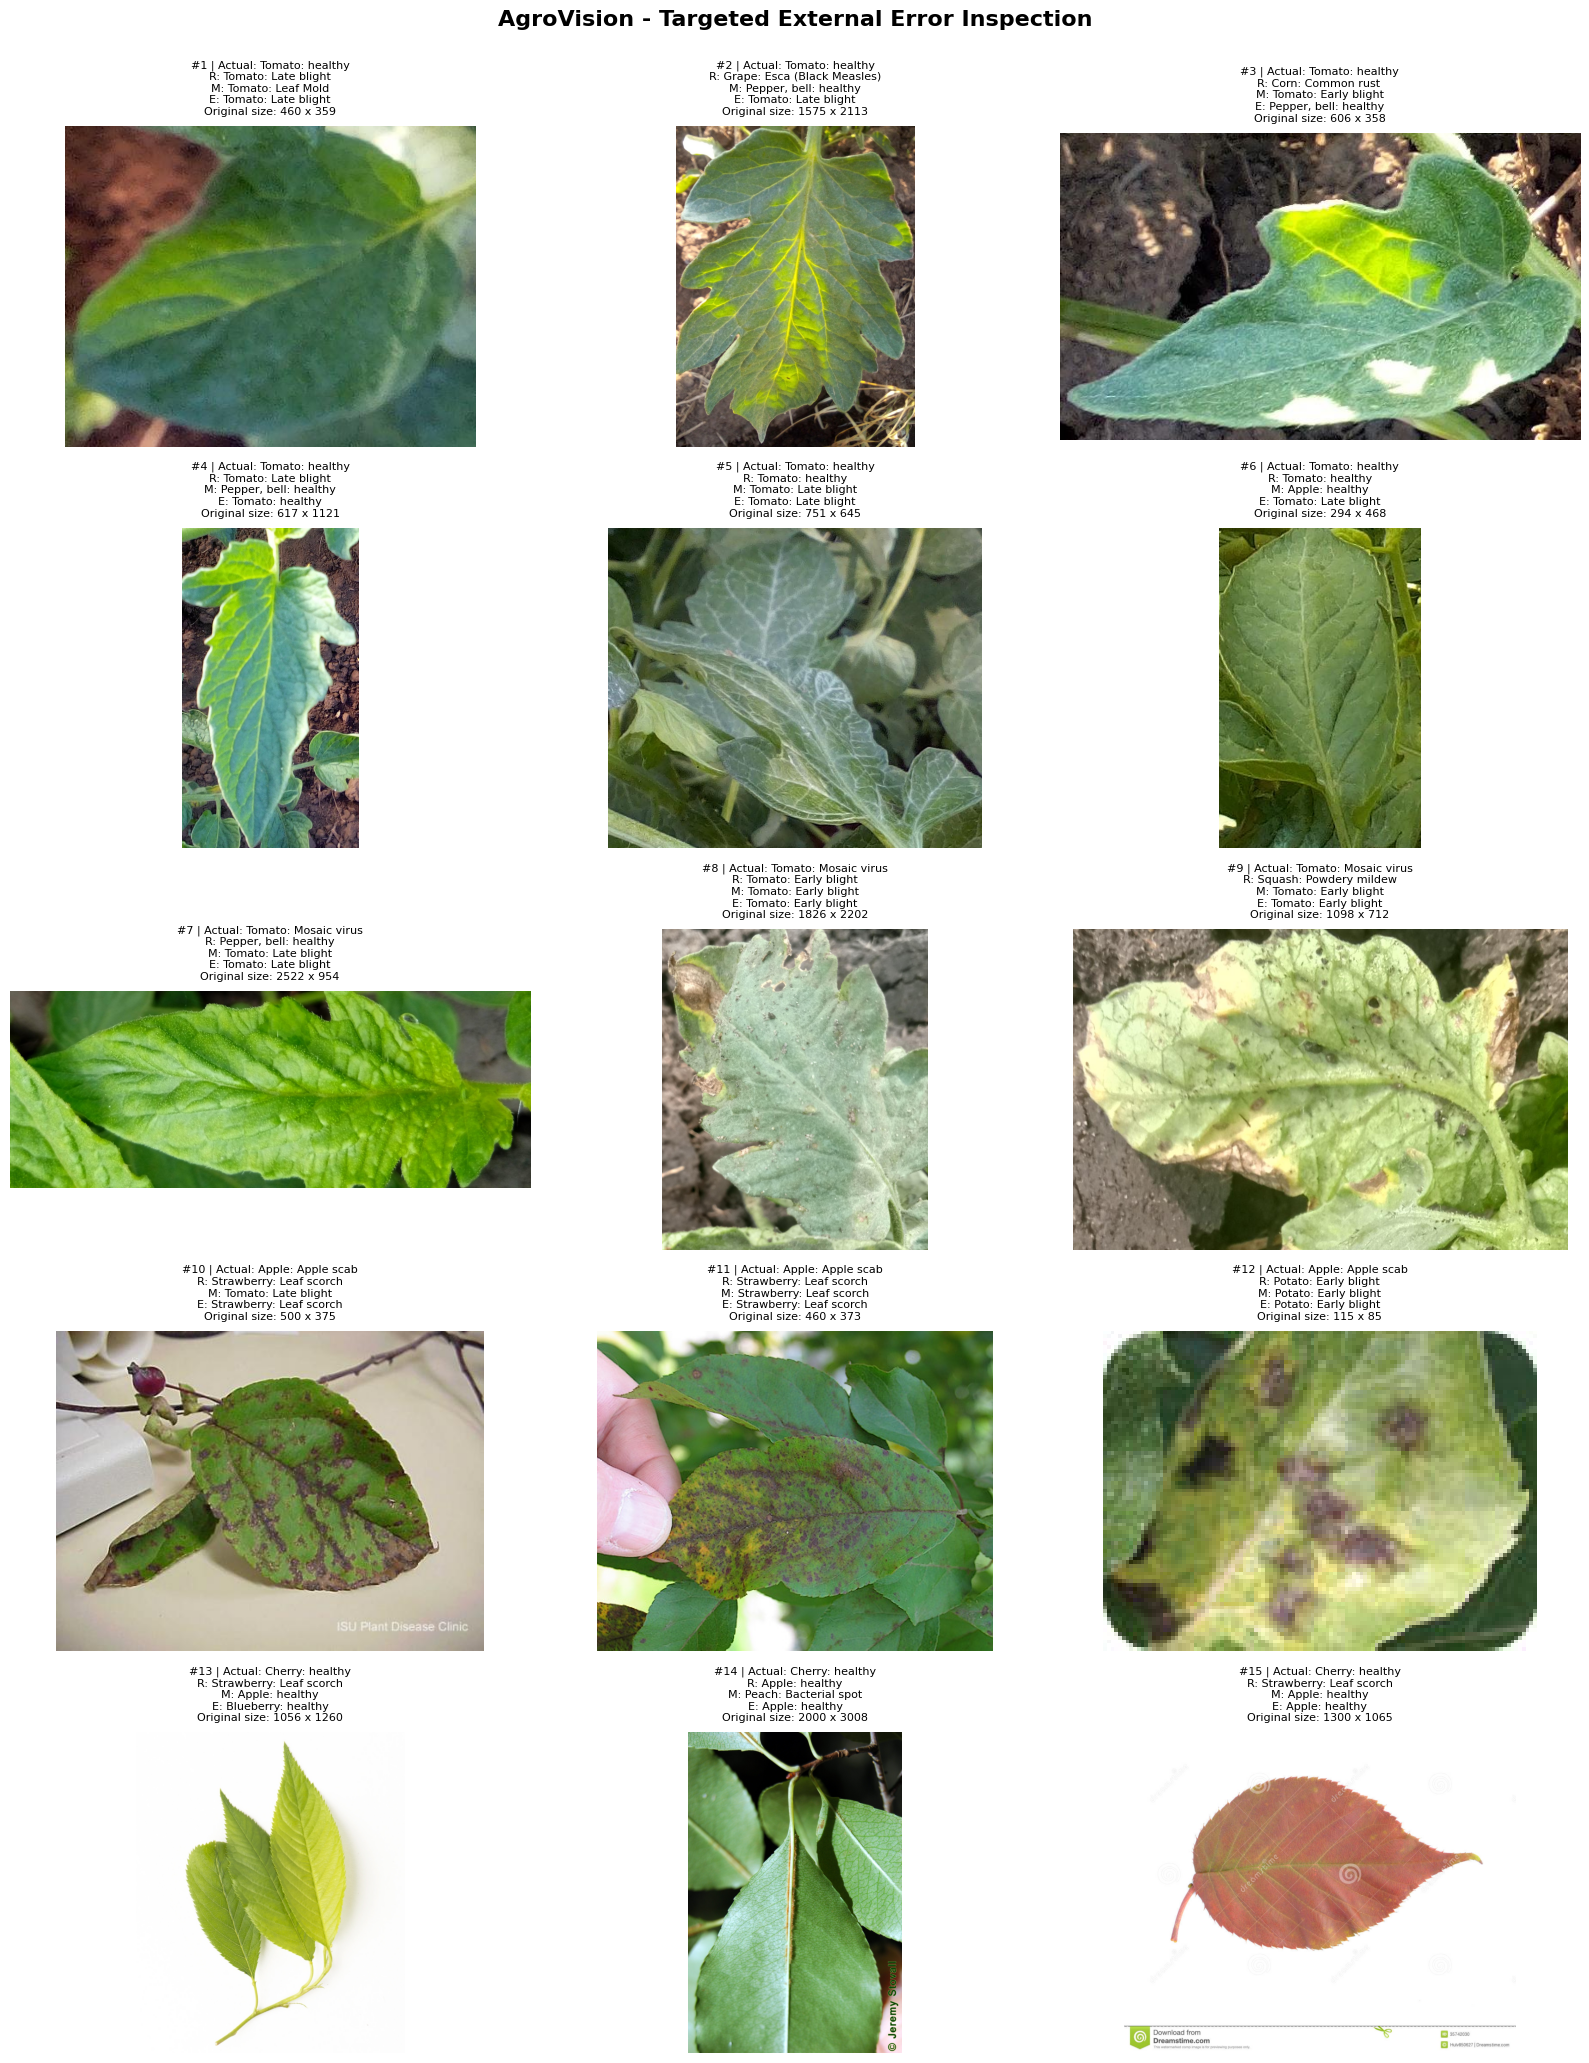


TARGETED VISUAL INSPECTION: PREPARED
External samples available: 740
Selected visual examples: 15
Model predictions reused: YES
Additional model inference: NO
Model retraining: NO
Original class labels modified: NO

Saved review CSV:
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/external_evaluation/external_targeted_visual_review.csv

Saved review image:
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/external_evaluation/external_targeted_visual_review.png


In [18]:
# ============================================================
# PHASE 6.5 - CELL 17
# Targeted visual inspection of external classification errors
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 65)
print("PHASE 6.5 - TARGETED EXTERNAL ERROR INSPECTION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Reconstruct aligned predictions across all three models
# ------------------------------------------------------------

review_sources = []
class_name_array = np.asarray(class_names, dtype=np.str_)

for dataset_name, data in external_datasets.items():

    review_frame = pd.DataFrame({
        "dataset": DATASET_DISPLAY_NAMES[dataset_name],
        "image_filepath": data["filepaths"],
        "source_image_filepath": data["source_paths"],
        "actual_class": data["true_classes"]
    })

    for model_name in MODEL_NAMES:

        prediction_path = (
            EXTERNAL_EVAL_DIR
            / f"{model_name}_{dataset_name}_predictions.npz"
        )

        with np.load(
            prediction_path,
            allow_pickle=False
        ) as saved:

            assert np.array_equal(
                saved["filepaths"],
                data["filepaths"]
            )

            assert np.array_equal(
                saved["true_labels"],
                data["true_labels"]
            )

            predicted = saved["predicted_labels"].copy()

            top_probability = np.max(
                saved["probabilities"],
                axis=1
            )

        review_frame[f"{model_name}_prediction"] = (
            class_name_array[predicted]
        )

        review_frame[f"{model_name}_top_probability"] = (
            top_probability
        )

        review_frame[f"{model_name}_correct"] = (
            predicted == data["true_labels"]
        )

    correctness_columns = [
        f"{name}_correct"
        for name in MODEL_NAMES
    ]

    review_frame["models_correct"] = (
        review_frame[correctness_columns]
        .sum(axis=1)
        .astype(int)
    )

    review_sources.append(review_frame)

external_joint_review_df = pd.concat(
    review_sources,
    ignore_index=True
)

assert len(external_joint_review_df) == 740

# ------------------------------------------------------------
# 2. Summarise agreement between model predictions
# ------------------------------------------------------------

print("\nMODEL CORRECTNESS AGREEMENT")

agreement_summary = (
    external_joint_review_df
    .groupby(
        ["dataset", "models_correct"]
    )
    .size()
    .reset_index(name="images")
)

display(agreement_summary)

# ------------------------------------------------------------
# 3. Define targeted inspection groups
# ------------------------------------------------------------

focus_groups = [
    {
        "dataset": "Cropped-FieldPlant",
        "class": "Tomato___healthy",
        "condition": "all_wrong",
        "count": 3,
        "focus": "FieldPlant Tomato Healthy - all wrong"
    },
    {
        "dataset": "Cropped-FieldPlant",
        "class": "Tomato___healthy",
        "condition": "any_correct",
        "count": 3,
        "focus": "FieldPlant Tomato Healthy - some correct"
    },
    {
        "dataset": "Cropped-FieldPlant",
        "class": "Tomato___Tomato_mosaic_virus",
        "condition": "all_wrong",
        "count": 3,
        "focus": "FieldPlant Tomato Mosaic Virus"
    },
    {
        "dataset": "Cropped-PlantDoc",
        "class": "Apple___Apple_scab",
        "condition": "all_wrong",
        "count": 3,
        "focus": "PlantDoc Apple Scab"
    },
    {
        "dataset": "Cropped-PlantDoc",
        "class": "Cherry_(including_sour)___healthy",
        "condition": "all_wrong",
        "count": 3,
        "focus": "PlantDoc Cherry Healthy"
    }
]

# ------------------------------------------------------------
# 4. Select reproducible examples
# ------------------------------------------------------------

review_samples = []

for group in focus_groups:

    subset = external_joint_review_df.loc[
        (external_joint_review_df["dataset"] == group["dataset"])
        & (external_joint_review_df["actual_class"] == group["class"])
    ].copy()

    if group["condition"] == "all_wrong":
        subset = subset[
            subset["models_correct"] == 0
        ]

    elif group["condition"] == "any_correct":
        subset = subset[
            subset["models_correct"] >= 1
        ]

    # Prioritise different source photographs.
    subset = (
        subset
        .sort_values("image_filepath")
        .drop_duplicates("source_image_filepath")
    )

    selection_count = min(
        group["count"],
        len(subset)
    )

    if selection_count == 0:
        print(f"No eligible images: {group['focus']}")
        continue

    selected = subset.sample(
        n=selection_count,
        random_state=42
    ).sort_values("image_filepath")

    selected = selected.copy()
    selected["review_focus"] = group["focus"]

    review_samples.append(selected)

    print(
        f"{group['focus']}: "
        f"{selection_count} selected"
    )

assert review_samples, "No review samples selected."

external_visual_review_df = pd.concat(
    review_samples,
    ignore_index=True
)

external_visual_review_df.insert(
    0,
    "review_id",
    np.arange(1, len(external_visual_review_df) + 1)
)

external_visual_review_df["review_status"] = (
    "Not yet manually reviewed"
)

external_visual_review_df["review_notes"] = ""

# ------------------------------------------------------------
# 5. Save the selected cases
# ------------------------------------------------------------

review_csv_path = (
    EXTERNAL_EVAL_DIR
    / "external_targeted_visual_review.csv"
)

external_visual_review_df.to_csv(
    review_csv_path,
    index=False
)

print("\nSELECTED REVIEW SAMPLES")
print("Total images:", len(external_visual_review_df))

display(
    external_visual_review_df[
        [
            "review_id",
            "review_focus",
            "actual_class",
            "models_correct"
        ]
    ]
)

# ------------------------------------------------------------
# 6. Display original external image crops
# ------------------------------------------------------------

def short_class_name(class_name):

    name = class_name.replace("___", ": ")
    name = name.replace("_", " ")

    name = name.replace(
        "Tomato: Tomato mosaic virus",
        "Tomato: Mosaic virus"
    )

    name = name.replace(
        "Cherry (including sour)",
        "Cherry"
    )

    name = name.replace(
        "Corn (maize)",
        "Corn"
    )

    return name


rows = len(focus_groups)
columns = 3

fig, axes = plt.subplots(
    rows,
    columns,
    figsize=(16, 21)
)

for ax in axes.flat:
    ax.axis("off")

for row_index, group in enumerate(focus_groups):

    subset = external_visual_review_df[
        external_visual_review_df["review_focus"]
        == group["focus"]
    ].reset_index(drop=True)

    for column_index, sample in subset.iterrows():

        if column_index >= columns:
            break

        ax = axes[row_index, column_index]

        with Image.open(sample["image_filepath"]) as image:
            image_rgb = image.convert("RGB")
            width, height = image_rgb.size
            ax.imshow(image_rgb)

        ax.axis("off")

        title_lines = [
            f"#{sample['review_id']} | "
            f"Actual: {short_class_name(sample['actual_class'])}",
            f"R: {short_class_name(sample['ResNet50_prediction'])}",
            f"M: {short_class_name(sample['MobileNetV2_prediction'])}",
            f"E: {short_class_name(sample['EfficientNetB0_prediction'])}",
            f"Original size: {width} x {height}"
        ]

        ax.set_title(
            "\n".join(title_lines),
            fontsize=8,
            pad=8
        )

        if column_index == 0:
            ax.set_ylabel(
                group["focus"],
                fontsize=10,
                fontweight="bold"
            )

fig.suptitle(
    "AgroVision - Targeted External Error Inspection",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

review_image_path = (
    EXTERNAL_EVAL_DIR
    / "external_targeted_visual_review.png"
)

fig.savefig(
    review_image_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. Verify saved outputs
# ------------------------------------------------------------

assert review_csv_path.is_file()
assert review_image_path.is_file()

print("\n" + "=" * 65)
print("TARGETED VISUAL INSPECTION: PREPARED")
print("=" * 65)

print("External samples available: 740")
print("Selected visual examples:", len(external_visual_review_df))
print("Model predictions reused: YES")
print("Additional model inference: NO")
print("Model retraining: NO")
print("Original class labels modified: NO")

print("\nSaved review CSV:")
print(review_csv_path)

print("\nSaved review image:")
print(review_image_path)

print("=" * 65)


In [19]:
# ============================================================
# PHASE 6.6 - CELL 18
# Model footprint and inference performance benchmarking
# ============================================================

import gc
import time
import numpy as np
import pandas as pd
import tensorflow as tf

print("=" * 65)
print("PHASE 6.6 - MODEL DEPLOYMENT BENCHMARK")
print("=" * 65)

# ------------------------------------------------------------
# 1. Define benchmark configuration
# ------------------------------------------------------------

DEPLOYMENT_DIR = PHASE6_DIR / "deployment_analysis"
DEPLOYMENT_DIR.mkdir(parents=True, exist_ok=True)

BENCHMARK_IMAGE_SIZE = (160, 160)
BENCHMARK_BATCH_SIZE = 32

WARMUP_RUNS = 4
SINGLE_IMAGE_RUNS = 15
BATCH_RUNS = 10

available_gpus = tf.config.list_physical_devices("GPU")

device_name = (
    "/GPU:0" if available_gpus else "/CPU:0"
)

print("\nBENCHMARK ENVIRONMENT")
print("TensorFlow:", tf.__version__)
print("Requested device:", device_name)
print("Available GPUs:", available_gpus)
print("Image size:", BENCHMARK_IMAGE_SIZE)
print("Single-image repetitions:", SINGLE_IMAGE_RUNS)
print("Batch repetitions:", BATCH_RUNS)
print("Warm-up runs per input shape:", WARMUP_RUNS)
print("Input pipeline included: NO")

# ------------------------------------------------------------
# 2. Create identical synthetic inputs for all models
# ------------------------------------------------------------

with tf.device(device_name):

    synthetic_batch = tf.random.stateless_uniform(
        shape=(BENCHMARK_BATCH_SIZE, 160, 160, 3),
        seed=(42, 7),
        minval=0,
        maxval=255,
        dtype=tf.float32
    )

    synthetic_single = synthetic_batch[:1]

assert tuple(synthetic_single.shape) == (1, 160, 160, 3)
assert tuple(synthetic_batch.shape) == (32, 160, 160, 3)

print("\nSynthetic benchmark inputs: VERIFIED")

# ------------------------------------------------------------
# 3. Define synchronised forward-pass timing
# ------------------------------------------------------------

def benchmark_forward_pass(
    inference_fn,
    input_tensor,
    repetitions
):

    # Warm up separately for each batch shape.
    # Exclude graph tracing and initial setup from timing.
    for _ in range(WARMUP_RUNS):

        output = inference_fn(input_tensor)

        # Synchronise GPU execution before continuing.
        _ = tf.reduce_sum(output).numpy()

    durations_ms = []

    for _ in range(repetitions):

        start_time = time.perf_counter()

        output = inference_fn(input_tensor)

        # Force completion of the forward pass.
        _ = tf.reduce_sum(output).numpy()

        elapsed_ms = (
            time.perf_counter() - start_time
        ) * 1000

        durations_ms.append(elapsed_ms)

    return np.asarray(
        durations_ms,
        dtype=np.float64
    )


# ------------------------------------------------------------
# 4. Benchmark each saved Stage 2 model independently
# ------------------------------------------------------------

deployment_records = []

for model_name in MODEL_NAMES:

    print("\n" + "-" * 65)
    print(f"MODEL: {model_name}")
    print("-" * 65)

    tf.keras.backend.clear_session()
    gc.collect()

    checkpoint_path = (
        EXPERIMENT_DIR
        / model_name
        / "stage2"
        / "best_model.keras"
    )

    assert checkpoint_path.is_file()

    checkpoint_size_mb = (
        checkpoint_path.stat().st_size / (1024 ** 2)
    )

    with tf.device(device_name):

        model = tf.keras.models.load_model(
            str(checkpoint_path),
            compile=False,
            safe_mode=True
        )

        assert tuple(model.input_shape) == (
            None, 160, 160, 3
        )

        assert tuple(model.output_shape) == (
            None, 38
        )

        parameter_count = int(
            model.count_params()
        )

        # Compile inference into a TensorFlow graph.
        # Augmentation remains disabled during inference.
        inference_fn = tf.function(
            lambda batch: model(batch, training=False),
            reduce_retracing=True
        )

        # Confirm expected output behaviour.
        verification_output = inference_fn(
            synthetic_single
        ).numpy()

        assert verification_output.shape == (1, 38)
        assert np.isfinite(verification_output).all()

        assert np.allclose(
            verification_output.sum(axis=1),
            1.0,
            atol=1e-3,
            rtol=0
        )

        print("\nCheckpoint loading: PASSED")
        print(f"Parameters: {parameter_count:,}")
        print(
            f"Checkpoint size: {checkpoint_size_mb:.2f} MB"
        )

        # ----------------------------------------------------
        # 5. Measure single-image inference latency
        # ----------------------------------------------------

        single_times = benchmark_forward_pass(
            inference_fn,
            synthetic_single,
            SINGLE_IMAGE_RUNS
        )

        single_median_ms = float(
            np.median(single_times)
        )

        single_p90_ms = float(
            np.percentile(single_times, 90)
        )

        # ----------------------------------------------------
        # 6. Measure batch-32 throughput
        # ----------------------------------------------------

        batch_times = benchmark_forward_pass(
            inference_fn,
            synthetic_batch,
            BATCH_RUNS
        )

        batch_median_ms = float(
            np.median(batch_times)
        )

        throughput = (
            BENCHMARK_BATCH_SIZE
            / (batch_median_ms / 1000)
        )

        assert single_median_ms > 0
        assert batch_median_ms > 0
        assert np.isfinite(throughput)

        print("\nINFERENCE PERFORMANCE")
        print(
            f"Single-image median: "
            f"{single_median_ms:.2f} ms"
        )
        print(
            f"Single-image P90: "
            f"{single_p90_ms:.2f} ms"
        )
        print(
            f"Batch-32 median: "
            f"{batch_median_ms:.2f} ms"
        )
        print(
            f"Batch throughput: "
            f"{throughput:.2f} images/second"
        )

        # ----------------------------------------------------
        # 7. Store deployment profile
        # ----------------------------------------------------

        deployment_records.append({
            "model": model_name,
            "parameters": parameter_count,
            "checkpoint_size_mb": checkpoint_size_mb,
            "single_image_median_ms": single_median_ms,
            "single_image_p90_ms": single_p90_ms,
            "batch32_median_ms": batch_median_ms,
            "batch32_throughput_images_per_sec": throughput,
            "requested_device": device_name,
            "tensorflow_version": tf.__version__
        })

    # Release model resources before loading next model.
    del model
    del inference_fn
    del verification_output

    tf.keras.backend.clear_session()
    gc.collect()

    print("\nModel memory released.")

# ------------------------------------------------------------
# 8. Create consolidated benchmark comparison
# ------------------------------------------------------------

deployment_df = pd.DataFrame(
    deployment_records
)

assert len(deployment_df) == 3
assert set(deployment_df["model"]) == set(MODEL_NAMES)

print("\n" + "=" * 65)
print("DEPLOYMENT BENCHMARK COMPARISON")
print("=" * 65)

display(
    deployment_df[
        [
            "model",
            "parameters",
            "checkpoint_size_mb",
            "single_image_median_ms",
            "single_image_p90_ms",
            "batch32_throughput_images_per_sec"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

deployment_path = (
    DEPLOYMENT_DIR
    / "model_deployment_benchmark.csv"
)

deployment_df.to_csv(
    deployment_path,
    index=False,
    float_format="%.6f"
)

assert deployment_path.is_file()

print("\nBenchmark results: SAVED")
print("File:", deployment_path)

# ------------------------------------------------------------
# 10. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PHASE 6.6 - DEPLOYMENT BENCHMARK COMPLETED")
print("=" * 65)

print("Models benchmarked: 3")
print("Benchmark input: Synthetic RGB images")
print("Input dimensions: 160 x 160")
print("Model retraining: NO")
print("PlantVillage test inference: NO")
print("External dataset inference: NO")
print("Image loading and network overhead measured: NO")

print("\nReady for consolidated model comparison.")
print("=" * 65)


PHASE 6.6 - MODEL DEPLOYMENT BENCHMARK

BENCHMARK ENVIRONMENT
TensorFlow: 2.21.0
Requested device: /GPU:0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Image size: (160, 160)
Single-image repetitions: 15
Batch repetitions: 10
Warm-up runs per input shape: 4
Input pipeline included: NO

Synthetic benchmark inputs: VERIFIED

-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------

Checkpoint loading: PASSED
Parameters: 23,665,586
Checkpoint size: 205.61 MB

INFERENCE PERFORMANCE
Single-image median: 11.14 ms
Single-image P90: 12.84 ms
Batch-32 median: 70.24 ms
Batch throughput: 455.61 images/second

Model memory released.

-----------------------------------------------------------------
MODEL: MobileNetV2
-----------------------------------------------------------------

Checkpoint loading: PASSED
Parameters: 2,306,662
Checkpoint size: 22.44 MB

INFERENCE PERF

,model,parameters,checkpoint_size_mb,single_image_median_ms,single_image_p90_ms,batch32_throughput_images_per_sec
0,ResNet50,23665586,205.61,11.14,12.84,455.61
1,MobileNetV2,2306662,22.44,5.94,7.08,1248.65
2,EfficientNetB0,4098249,40.72,8.92,9.19,852.98



Benchmark results: SAVED
File: /content/drive/MyDrive/AgroVision_FYP2/model_evaluation/deployment_analysis/model_deployment_benchmark.csv

PHASE 6.6 - DEPLOYMENT BENCHMARK COMPLETED
Models benchmarked: 3
Benchmark input: Synthetic RGB images
Input dimensions: 160 x 160
Model retraining: NO
PlantVillage test inference: NO
External dataset inference: NO
Image loading and network overhead measured: NO

Ready for consolidated model comparison.


In [23]:
# ============================================================
# PHASE 6.6 - CELL 19
# Consolidated classification, generalisation and deployment
# comparison
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("PHASE 6.6 - CONSOLIDATED MODEL COMPARISON")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load the saved results from previous evaluation cells
# ------------------------------------------------------------

source_files = {
    "controlled": (
        CONTROLLED_DIR / "plantvillage_test_metrics.csv"
    ),
    "per_class": (
        CONTROLLED_DIR / "plantvillage_per_class_metrics.csv"
    ),
    "external": (
        EXTERNAL_EVAL_DIR / "external_dataset_metrics.csv"
    ),
    "generalisation": (
        EXTERNAL_EVAL_DIR
        / "class_matched_generalisation_comparison.csv"
    ),
    "deployment": (
        DEPLOYMENT_DIR / "model_deployment_benchmark.csv"
    )
}

assert all(
    path.is_file()
    for path in source_files.values()
), "One or more saved evaluation results are missing."

results = {
    name: pd.read_csv(path)
    for name, path in source_files.items()
}

print("\nEVALUATION SOURCES")
for name, path in source_files.items():
    print(f"{name}: VERIFIED")

# ------------------------------------------------------------
# 2. Prepare model-indexed result tables
# ------------------------------------------------------------

controlled = results["controlled"].set_index("model")

external = results["external"].set_index(
    ["dataset", "model"]
)

generalisation = results["generalisation"].set_index(
    ["dataset", "model"]
)

deployment = results["deployment"].set_index("model")

per_class = results["per_class"]

assert set(controlled.index) == set(MODEL_NAMES)
assert set(deployment.index) == set(MODEL_NAMES)

assert len(controlled) == 3
assert len(external) == 6
assert len(generalisation) == 6
assert len(deployment) == 3

assert len(per_class) == 114

# ------------------------------------------------------------
# 3. Consolidate all comparison dimensions
# ------------------------------------------------------------

comparison_records = []

for model_name in MODEL_NAMES:

    pv = controlled.loc[model_name]
    hardware = deployment.loc[model_name]

    plantdoc = external.loc[
        ("Cropped-PlantDoc", model_name)
    ]

    fieldplant = external.loc[
        ("Cropped-FieldPlant", model_name)
    ]

    plantdoc_gap = generalisation.loc[
        ("Cropped-PlantDoc", model_name)
    ]

    fieldplant_gap = generalisation.loc[
        ("Cropped-FieldPlant", model_name)
    ]

    class_rows = per_class.loc[
        per_class["model"] == model_name
    ]

    assert len(class_rows) == 38
    assert int(class_rows["support"].sum()) == 8151

    # Macro F1 gives equal weight to every PV class.
    pv_macro_f1 = float(
        class_rows["f1_score"].mean() * 100
    )

    # Ensure external and generalisation records agree.
    for ext_row, gap_row in [
        (plantdoc, plantdoc_gap),
        (fieldplant, fieldplant_gap)
    ]:
        assert np.isclose(
            ext_row["accuracy"] * 100,
            gap_row["external_accuracy_pct"],
            atol=1e-6
        )

    comparison_records.append({
        "model": model_name,

        # Controlled PlantVillage performance
        "pv_accuracy_pct": pv["accuracy"] * 100,
        "pv_weighted_f1_pct": pv["weighted_f1"] * 100,
        "pv_macro_f1_pct": pv_macro_f1,

        # External classification performance
        "plantdoc_accuracy_pct":
            plantdoc["accuracy"] * 100,
        "fieldplant_accuracy_pct":
            fieldplant["accuracy"] * 100,

        # Class-distribution-adjusted gaps
        "plantdoc_adjusted_gap_pp":
            plantdoc_gap["adjusted_gap_pp"],
        "fieldplant_adjusted_gap_pp":
            fieldplant_gap["adjusted_gap_pp"],

        # Out-of-coverage predictions
        "plantdoc_outside_coverage_pct":
            plantdoc["outside_coverage_percentage"],
        "fieldplant_outside_coverage_pct":
            fieldplant["outside_coverage_percentage"],

        # Deployment benchmark
        "parameters": int(hardware["parameters"]),
        "checkpoint_size_mb":
            hardware["checkpoint_size_mb"],
        "single_image_median_ms":
            hardware["single_image_median_ms"],
        "single_image_p90_ms":
            hardware["single_image_p90_ms"],
        "batch32_throughput":
            hardware["batch32_throughput_images_per_sec"]
    })

model_comparison_df = pd.DataFrame(
    comparison_records
)

assert len(model_comparison_df) == 3

# ------------------------------------------------------------
# 4. Display controlled and external performance
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("A. CLASSIFICATION PERFORMANCE")
print("=" * 65)

accuracy_columns = {
    "model": "Model",
    "pv_accuracy_pct": "PlantVillage Acc (%)",
    "pv_weighted_f1_pct": "PV Weighted F1 (%)",
    "pv_macro_f1_pct": "PV Macro F1 (%)",
    "plantdoc_accuracy_pct": "PlantDoc Acc (%)",
    "fieldplant_accuracy_pct": "FieldPlant Acc (%)"
}

display(
    model_comparison_df[
        list(accuracy_columns.keys())
    ].rename(
        columns=accuracy_columns
    ).round(2)
)

# ------------------------------------------------------------
# 5. Display external generalisation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("B. EXTERNAL GENERALISATION")
print("=" * 65)

generalisation_columns = {
    "model": "Model",
    "plantdoc_adjusted_gap_pp": "PlantDoc Gap (pp)",
    "fieldplant_adjusted_gap_pp": "FieldPlant Gap (pp)",
    "plantdoc_outside_coverage_pct":
        "PlantDoc Outside (%)",
    "fieldplant_outside_coverage_pct":
        "FieldPlant Outside (%)"
}

display(
    model_comparison_df[
        list(generalisation_columns.keys())
    ].rename(
        columns=generalisation_columns
    ).round(2)
)

# ------------------------------------------------------------
# 6. Display deployment performance
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C. COMPUTATIONAL AND DEPLOYMENT PERFORMANCE")
print("=" * 65)

deployment_columns = {
    "model": "Model",
    "parameters": "Parameters",
    "checkpoint_size_mb": "Checkpoint (MB)",
    "single_image_median_ms": "Median Latency (ms)",
    "single_image_p90_ms": "P90 Latency (ms)",
    "batch32_throughput": "Images/Second"
}

display(
    model_comparison_df[
        list(deployment_columns.keys())
    ].rename(
        columns=deployment_columns
    ).round(2)
)

# ------------------------------------------------------------
# 7. Identify leaders by individual criterion
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("D. BEST MODEL BY INDIVIDUAL CRITERION")
print("=" * 65)

criteria = [
    ("PlantVillage accuracy", "pv_accuracy_pct", True),
    ("PlantDoc accuracy", "plantdoc_accuracy_pct", True),
    ("FieldPlant accuracy", "fieldplant_accuracy_pct", True),
    ("Smallest checkpoint", "checkpoint_size_mb", False),
    ("Lowest median latency", "single_image_median_ms", False),
    ("Highest batch throughput", "batch32_throughput", True)
]

leaders = []

for criterion, column, higher_is_better in criteria:

    if higher_is_better:
        best_index = model_comparison_df[column].idxmax()
    else:
        best_index = model_comparison_df[column].idxmin()

    leaders.append({
        "Criterion": criterion,
        "Leading model":
            model_comparison_df.loc[best_index, "model"]
    })

display(pd.DataFrame(leaders))

# ------------------------------------------------------------
# 8. Save the consolidated comparison
# ------------------------------------------------------------

comparison_path = (
    DEPLOYMENT_DIR
    / "consolidated_model_comparison.csv"
)

model_comparison_df.to_csv(
    comparison_path,
    index=False,
    float_format="%.9f"
)

assert comparison_path.is_file()

print("\n" + "=" * 65)
print("PHASE 6.6 - CONSOLIDATED COMPARISON COMPLETED")
print("=" * 65)

print("Models compared: 3")
print("Source result files: 5")
print("Comparison dimensions: 3")
print("Consolidated file: SAVED")
print("Additional inference: NO")
print("Model retraining: NO")
print("Arbitrary model ranking weights applied: NO")

print("\nFile:")
print(comparison_path)

print("\nReady for Phase 6.7 - Final Model Selection.")
print("=" * 65)


PHASE 6.6 - CONSOLIDATED MODEL COMPARISON

EVALUATION SOURCES
controlled: VERIFIED
per_class: VERIFIED
external: VERIFIED
generalisation: VERIFIED
deployment: VERIFIED

A. CLASSIFICATION PERFORMANCE


,Model,PlantVillage Acc (%),PV Weighted F1 (%),PV Macro F1 (%),PlantDoc Acc (%),FieldPlant Acc (%)
0,ResNet50,96.95,96.97,96.76,17.80,29.96
1,MobileNetV2,96.83,96.85,96.17,25.42,26.79
2,EfficientNetB0,98.52,98.52,98.25,27.12,27.78



B. EXTERNAL GENERALISATION


,Model,PlantDoc Gap (pp),FieldPlant Gap (pp),PlantDoc Outside (%),FieldPlant Outside (%)
0,ResNet50,-79.04,-68.60,29.24,63.69
1,MobileNetV2,-70.47,-71.46,25.85,56.75
2,EfficientNetB0,-70.98,-69.93,14.41,69.64



C. COMPUTATIONAL AND DEPLOYMENT PERFORMANCE


,Model,Parameters,Checkpoint (MB),Median Latency (ms),P90 Latency (ms),Images/Second
0,ResNet50,23665586,205.61,11.14,12.84,455.61
1,MobileNetV2,2306662,22.44,5.94,7.08,1248.65
2,EfficientNetB0,4098249,40.72,8.92,9.19,852.98



D. BEST MODEL BY INDIVIDUAL CRITERION


,Criterion,Leading model
0,PlantVillage accuracy,EfficientNetB0
1,PlantDoc accuracy,EfficientNetB0
2,FieldPlant accuracy,ResNet50
3,Smallest checkpoint,MobileNetV2
4,Lowest median latency,MobileNetV2
5,Highest batch throughput,MobileNetV2



PHASE 6.6 - CONSOLIDATED COMPARISON COMPLETED
Models compared: 3
Source result files: 5
Comparison dimensions: 3
Consolidated file: SAVED
Additional inference: NO
Model retraining: NO
Arbitrary model ranking weights applied: NO

File:
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/deployment_analysis/consolidated_model_comparison.csv

Ready for Phase 6.7 - Final Model Selection.


In [24]:
# ============================================================
# PHASE 6.7 - CELL 20
# Final model selection and justification
# ============================================================

import json
import numpy as np
import pandas as pd
from datetime import datetime, timezone

print("=" * 65)
print("PHASE 6.7 - FINAL MODEL SELECTION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load the verified consolidated comparison
# ------------------------------------------------------------

comparison_path = (
    DEPLOYMENT_DIR
    / "consolidated_model_comparison.csv"
)

assert comparison_path.is_file()

final_comparison = pd.read_csv(comparison_path)

assert len(final_comparison) == 3
assert final_comparison["model"].is_unique
assert set(final_comparison["model"]) == set(MODEL_NAMES)

# Independently verify corrected macro F1 percentages.
per_class_saved = pd.read_csv(
    CONTROLLED_DIR
    / "plantvillage_per_class_metrics.csv"
)

expected_macro_f1 = (
    per_class_saved.groupby("model")["f1_score"]
    .mean() * 100
)

for _, row in final_comparison.iterrows():
    assert np.isclose(
        row["pv_macro_f1_pct"],
        expected_macro_f1.loc[row["model"]],
        atol=1e-6
    )

print("\nConsolidated comparison: VERIFIED")
print("Macro F1 percentage correction: VERIFIED")

# ------------------------------------------------------------
# 2. Identify the selected prototype model
# ------------------------------------------------------------

SELECTED_MODEL = "EfficientNetB0"

model_data = final_comparison.set_index("model")

selected = model_data.loc[SELECTED_MODEL]
resnet = model_data.loc["ResNet50"]
mobile = model_data.loc["MobileNetV2"]

# Confirm the evidence supporting the decision.
assert selected["pv_accuracy_pct"] == (
    model_data["pv_accuracy_pct"].max()
)

assert selected["pv_weighted_f1_pct"] == (
    model_data["pv_weighted_f1_pct"].max()
)

assert selected["pv_macro_f1_pct"] == (
    model_data["pv_macro_f1_pct"].max()
)

assert selected["plantdoc_accuracy_pct"] == (
    model_data["plantdoc_accuracy_pct"].max()
)

assert (
    selected["checkpoint_size_mb"]
    < resnet["checkpoint_size_mb"]
)

assert (
    selected["single_image_median_ms"]
    < resnet["single_image_median_ms"]
)

# Record important trade-offs rather than hiding them.
assert (
    selected["fieldplant_accuracy_pct"]
    < resnet["fieldplant_accuracy_pct"]
)

assert (
    selected["single_image_median_ms"]
    > mobile["single_image_median_ms"]
)

selected_checkpoint = (
    EXPERIMENT_DIR
    / SELECTED_MODEL
    / "stage2"
    / "best_model.keras"
)

assert selected_checkpoint.is_file()

print("\nSELECTED MODEL:", SELECTED_MODEL)
print("Checkpoint:", selected_checkpoint)
print("Selection evidence: VERIFIED")

# ------------------------------------------------------------
# 3. Record decision and supporting evidence
# ------------------------------------------------------------

selection_record = {
    "project": "AgroVision FYP2",
    "phase": "6.7 - Final Model Selection",
    "recorded_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "selected_model": SELECTED_MODEL,
    "selected_checkpoint": str(selected_checkpoint),
    "checkpoint_stage": "Stage 2",
    "selection_purpose": "Research prototype",
    "field_deployment_validated": False,

    "controlled_evaluation": {
        "dataset": "PlantVillage",
        "test_images": 8151,
        "classes": 38,
        "accuracy_pct": float(
            selected["pv_accuracy_pct"]
        ),
        "weighted_f1_pct": float(
            selected["pv_weighted_f1_pct"]
        ),
        "macro_f1_pct": float(
            selected["pv_macro_f1_pct"]
        )
    },

    "external_evaluation": {
        "plantdoc_images": 236,
        "plantdoc_accuracy_pct": float(
            selected["plantdoc_accuracy_pct"]
        ),
        "fieldplant_crops": 504,
        "fieldplant_source_photographs": 289,
        "fieldplant_accuracy_pct": float(
            selected["fieldplant_accuracy_pct"]
        ),
        "plantdoc_adjusted_gap_pp": float(
            selected["plantdoc_adjusted_gap_pp"]
        ),
        "fieldplant_adjusted_gap_pp": float(
            selected["fieldplant_adjusted_gap_pp"]
        )
    },

    "deployment_benchmark": {
        "parameters": int(selected["parameters"]),
        "checkpoint_size_mb": float(
            selected["checkpoint_size_mb"]
        ),
        "single_image_median_ms": float(
            selected["single_image_median_ms"]
        ),
        "batch32_throughput": float(
            selected["batch32_throughput"]
        ),
        "benchmark_scope": (
            "Colab GPU model forward pass on synthetic "
            "preloaded tensors; excludes web and I/O overhead"
        )
    },

    "selection_justification": [
        "Highest controlled PlantVillage accuracy "
        "and F1-scores among the three candidates.",

        "Highest Cropped-PlantDoc accuracy among "
        "the evaluated candidates.",

        "Smaller checkpoint and lower measured "
        "latency than ResNet50.",

        "Reasonable classification-performance and "
        "computational-efficiency compromise for "
        "the AgroVision research prototype."
    ],

    "alternative_model_tradeoffs": {
        "ResNet50": (
            "Highest FieldPlant accuracy, but larger "
            "checkpoint and slower inference."
        ),
        "MobileNetV2": (
            "Smallest checkpoint and fastest inference, "
            "but lower controlled and PlantDoc performance."
        )
    },

    "limitations": [
        "External classification accuracy remains low "
        "on both evaluated datasets.",

        "External results do not establish reliable "
        "real-world disease diagnosis.",

        "External datasets differ in class coverage, "
        "sampling and image conditions.",

        "FieldPlant includes multiple crops from "
        "some source photographs.",

        "Final architecture selection considered the "
        "reserved test results, introducing potential "
        "model-selection bias.",

        "GPU benchmark latency does not represent "
        "complete web application response time."
    ],

    "model_modification_performed": False,
    "additional_inference_performed": False
}

# ------------------------------------------------------------
# 4. Save the machine-readable decision record
# ------------------------------------------------------------

selection_json_path = (
    DEPLOYMENT_DIR / "final_model_selection.json"
)

with open(
    selection_json_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        selection_record,
        file,
        indent=4,
        ensure_ascii=False
    )

with open(
    selection_json_path,
    "r",
    encoding="utf-8"
) as file:
    saved_record = json.load(file)

assert saved_record == selection_record

print("\nSelection JSON: SAVED AND VERIFIED")

# ------------------------------------------------------------
# 5. Prepare a human-readable FYP2 justification
# ------------------------------------------------------------

justification = f"""# AgroVision FYP2 - Final Model Selection

## Selected Model

**EfficientNetB0 (Stage 2)**

**Purpose:** AgroVision research prototype.

This selection does not establish suitability for
reliable real-world field disease diagnosis.

## Controlled PlantVillage Performance

The selected model achieved:

- Accuracy: {selected['pv_accuracy_pct']:.2f}%
- Weighted F1-score: {selected['pv_weighted_f1_pct']:.2f}%
- Macro F1-score: {selected['pv_macro_f1_pct']:.2f}%

These were the highest controlled classification
results among the three evaluated architectures.

## External Dataset Performance

- Cropped-PlantDoc accuracy:
  {selected['plantdoc_accuracy_pct']:.2f}%

- Cropped-FieldPlant accuracy:
  {selected['fieldplant_accuracy_pct']:.2f}%

- PlantDoc adjusted accuracy gap:
  {selected['plantdoc_adjusted_gap_pp']:+.2f}
  percentage points

- FieldPlant adjusted accuracy gap:
  {selected['fieldplant_adjusted_gap_pp']:+.2f}
  percentage points

The external results demonstrate substantial
performance limitations under the evaluated
external dataset conditions.

The adjusted gaps account for external class
proportions but do not isolate domain shift
from other dataset differences.

## Computational Requirements

- Parameters: {int(selected['parameters']):,}
- Saved checkpoint:
  {selected['checkpoint_size_mb']:.2f} MB
- Median single-image forward pass:
  {selected['single_image_median_ms']:.2f} ms
- Batch throughput:
  {selected['batch32_throughput']:.2f} images/second

The benchmark was conducted using synthetic
preloaded RGB tensors on the current Colab GPU.

It excludes image loading, network transfer
and web application overhead.

## Model Selection Justification

EfficientNetB0 was selected because it provided
the highest controlled PlantVillage accuracy,
weighted F1-score and macro F1-score, together
with the highest accuracy on Cropped-PlantDoc.

Although ResNet50 achieved slightly higher
accuracy on Cropped-FieldPlant, EfficientNetB0
had a substantially smaller checkpoint and
lower measured inference latency.

MobileNetV2 offered the greatest computational
efficiency, but its controlled classification
performance was lower.

Considering the evaluated performance and
computational requirements together,
EfficientNetB0 was considered the most
appropriate candidate for implementing the
AgroVision research prototype.

No arbitrary weighted ranking score was used.

## Limitations

1. All three architectures showed poor external
   classification performance compared with
   their controlled PlantVillage results.

2. EfficientNetB0 cannot currently be presented
   as a reliable field disease diagnosis model.

3. External dataset class coverage and image
   conditions differ from PlantVillage.

4. Cropped-FieldPlant samples are not all
   independent source photographs.

5. Stage 2 checkpoints were selected using
   validation loss, but final architecture
   selection considered held-out test results.
   This may introduce model-selection bias.

6. The inference benchmark does not measure
   end-to-end website response time.

## Final Decision

**Selected architecture:** EfficientNetB0

**Selected checkpoint:** Stage 2 best_model.keras

**Application:** AgroVision research prototype

**Field deployment readiness:** Not established

The selected model will support prototype
integration and demonstration, with the
external generalisation limitations clearly
reported.
"""

selection_md_path = (
    DEPLOYMENT_DIR / "final_model_selection_justification.md"
)

selection_md_path.write_text(
    justification,
    encoding="utf-8"
)

assert selection_md_path.is_file()

print("Justification Markdown: SAVED")

# ------------------------------------------------------------
# 6. Display final decision summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL MODEL SELECTION SUMMARY")
print("=" * 65)

print("Selected model:", SELECTED_MODEL)
print("Checkpoint stage: Stage 2")
print("Purpose: AgroVision research prototype")
print("Field deployment readiness: NOT ESTABLISHED")

print("\nSELECTION EVIDENCE")
print(
    f"PlantVillage accuracy: "
    f"{selected['pv_accuracy_pct']:.2f}%"
)
print(
    f"PlantVillage weighted F1: "
    f"{selected['pv_weighted_f1_pct']:.2f}%"
)
print(
    f"PlantVillage macro F1: "
    f"{selected['pv_macro_f1_pct']:.2f}%"
)
print(
    f"PlantDoc accuracy: "
    f"{selected['plantdoc_accuracy_pct']:.2f}%"
)
print(
    f"FieldPlant accuracy: "
    f"{selected['fieldplant_accuracy_pct']:.2f}%"
)
print(
    f"Checkpoint size: "
    f"{selected['checkpoint_size_mb']:.2f} MB"
)

print("\n" + "=" * 65)
print("PHASE 6.7 - MODEL SELECTION RECORDED")
print("=" * 65)

print("Selection record: SAVED")
print("Written justification: SAVED")
print("Checkpoint modified: NO")
print("Additional inference: NO")
print("Model retraining: NO")

print("\nFiles:")
print(selection_json_path)
print(selection_md_path)

print("=" * 65)


PHASE 6.7 - FINAL MODEL SELECTION

Consolidated comparison: VERIFIED
Macro F1 percentage correction: VERIFIED

SELECTED MODEL: EfficientNetB0
Checkpoint: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/best_model.keras
Selection evidence: VERIFIED

Selection JSON: SAVED AND VERIFIED
Justification Markdown: SAVED

FINAL MODEL SELECTION SUMMARY
Selected model: EfficientNetB0
Checkpoint stage: Stage 2
Purpose: AgroVision research prototype
Field deployment readiness: NOT ESTABLISHED

SELECTION EVIDENCE
PlantVillage accuracy: 98.52%
PlantVillage weighted F1: 98.52%
PlantVillage macro F1: 98.25%
PlantDoc accuracy: 27.12%
FieldPlant accuracy: 27.78%
Checkpoint size: 40.72 MB

PHASE 6.7 - MODEL SELECTION RECORDED
Selection record: SAVED
Written justification: SAVED
Checkpoint modified: NO
Additional inference: NO
Model retraining: NO

Files:
/content/drive/MyDrive/AgroVision_FYP2/model_evaluation/deployment_analysis/final_model_selection.json
/content/drive/MyDr